In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 200           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
NUM_CLASSES = 10
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 32

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 200
Generator feature maps: 64
Discriminator feature maps: 32
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    def __init__(self, noise_dim, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes
        input_channels = noise_dim + num_classes

        self.net = nn.Sequential(
            nn.Unflatten(1, (input_channels, 1, 1)),

            nn.ConvTranspose2d(input_channels, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise, labels):
        class_vectors = F.one_hot(labels, num_classes=self.num_classes).to(noise.dtype)
        return self.net(torch.cat((noise, class_vectors), dim=1))


In [6]:
class Discriminator(nn.Module):
    def __init__(self, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes

        self.net = nn.Sequential(
            nn.Conv2d(1 + num_classes, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, data, labels):
        class_maps = F.one_hot(labels, num_classes=self.num_classes).to(data.dtype)
        class_maps = class_maps[:, :, None, None].expand(-1, -1, data.size(2), data.size(3))
        return self.net(torch.cat((data, class_maps), dim=1))


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS, NUM_CLASSES)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS, NUM_CLASSES)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 295,553
Discriminator parameters: 39,137
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(26, 1, 1))
    (1): ConvTranspose2d(26, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(11, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
def visualize_class_samples(classes, samples_per_class=5):
    class_labels = np.repeat(classes, samples_per_class)
    samples = generate_samples(len(class_labels), classes=class_labels)
    fig, axes = plt.subplots(
        len(classes), samples_per_class,
        figsize=(samples_per_class * 2, len(classes) * 2), squeeze=False,
    )

    for row, class_label in enumerate(classes):
        for column in range(samples_per_class):
            sample_index = row * samples_per_class + column
            axes[row, column].imshow(samples[sample_index].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
            axes[row, column].set_title(f'Class {class_label}')
            axes[row, column].axis('off')

    fig.tight_layout()
    plt.show()


In [9]:
def train_discriminator(real_data, class_labels):
    optimizer_D.zero_grad()
    real_data = real_data.to(device).float()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = real_data.size(0)

    real_output = discriminator(real_data, class_labels)
    real_targets = torch.ones_like(real_output)
    real_loss = criterion(real_output, real_targets)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    with torch.no_grad():
        fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    fake_targets = torch.zeros_like(fake_output)
    fake_loss = criterion(fake_output, fake_targets)

    d_loss = real_loss + fake_loss
    d_loss.backward()
    optimizer_D.step()
    return d_loss.item()


def evaluate_discriminator(real_data, class_labels):
    with torch.no_grad():
        real_data = real_data.to(device).float()
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = real_data.size(0)

        real_output = discriminator(real_data, class_labels)
        real_targets = torch.ones_like(real_output)
        real_loss = criterion(real_output, real_targets)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        fake_targets = torch.zeros_like(fake_output)
        fake_loss = criterion(fake_output, fake_targets)
        d_loss = real_loss + fake_loss

    return d_loss.item()


In [10]:
def train_generator(class_labels):
    optimizer_G.zero_grad()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = class_labels.size(0)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    real_targets = torch.ones_like(fake_output)
    g_loss = criterion(fake_output, real_targets)

    g_loss.backward()
    optimizer_G.step()
    return g_loss.item()


def evaluate_generator(class_labels):
    with torch.no_grad():
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = class_labels.size(0)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        real_targets = torch.ones_like(fake_output)
        g_loss = criterion(fake_output, real_targets)

    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, labels)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(labels)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, labels)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(labels)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000, classes=None):
    if isinstance(num_samples, bool) or not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    if classes is None:
        class_labels = torch.randint(NUM_CLASSES, (num_samples,), device=device)
    else:
        class_labels = torch.as_tensor(classes, device=device)
        if class_labels.dtype == torch.bool or class_labels.is_floating_point() or class_labels.is_complex():
            raise ValueError('classes must contain integer class labels')
        if class_labels.ndim == 0:
            class_labels = class_labels.repeat(num_samples)
        if class_labels.ndim != 1 or class_labels.numel() != num_samples:
            raise ValueError('Provide one class or one class per generated sample')
        if torch.any((class_labels < 0) | (class_labels >= NUM_CLASSES)):
            raise ValueError(f'classes must be between 0 and {NUM_CLASSES - 1}')
        class_labels = class_labels.long()

    was_training = generator.training
    generator.eval()
    try:
        with torch.no_grad():
            samples = []
            for start in range(0, num_samples, BATCH_SIZE):
                batch_labels = class_labels[start:start + BATCH_SIZE]
                noise = torch.randn(len(batch_labels), NOISE_DIM, device=device)
                samples.append(generator(noise, batch_labels).flatten(1).cpu())
            return torch.cat(samples).numpy()
    finally:
        generator.train(was_training)


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline


In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_classes = np.arange(2000) % NUM_CLASSES
    generated_samples = generate_samples(2000, classes=generated_classes)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    visualize_class_samples(list(range(NUM_CLASSES)), samples_per_class=2)


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.415682	G_loss: 0.739531
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.386008	G_loss: 0.696538
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.387862	G_loss: 0.690690
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.389541	G_loss: 0.692954
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.388862	G_loss: 0.691154
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.386871	G_loss: 0.693010
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.388186	G_loss: 0.695932
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.387595	G_loss: 0.693799
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.387084	G_loss: 0.694224
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.386983	G_loss: 0.693771
====> Epoch: 1 Train D_loss: 1.3878, Train G_loss: 0.6942
====> Epoch: 1 Val D_loss: 1.3862, Val G_loss: 0.6930
📈 Epoch 1 Summary:
   Train D Loss: 1.3878, Val D Loss: 1.3862
   Train G Loss: 0.6942, Val G Loss: 0.6930

📊 Epoch 2/200
------------------------

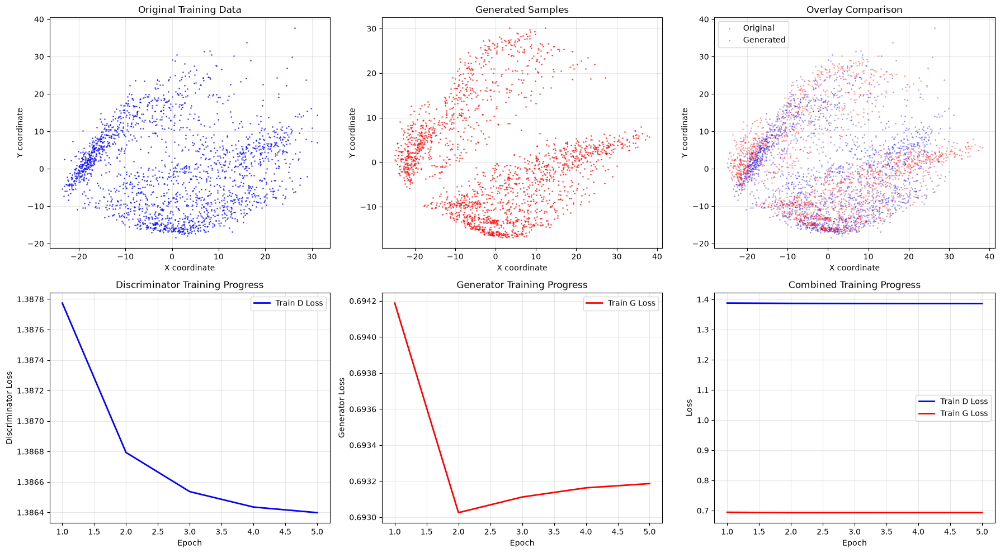

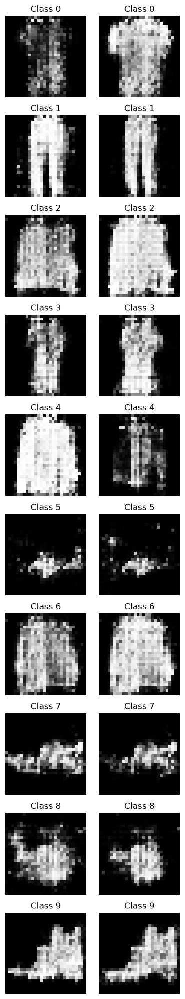

📈 Epoch 5 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3866
   Train G Loss: 0.6932, Val G Loss: 0.6926

📊 Epoch 6/200
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.386297	G_loss: 0.692918
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.386330	G_loss: 0.693130
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.386253	G_loss: 0.693018
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.386335	G_loss: 0.693256
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.386255	G_loss: 0.692186
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.386384	G_loss: 0.692845
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.386345	G_loss: 0.694003
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.386467	G_loss: 0.693181
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.386304	G_loss: 0.693624
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.386400	G_loss: 0.694356
====> Epoch: 6 Train D_loss: 1.3864, Train G_loss: 0.6931
====> Epoch: 6 Val D_loss: 1.3866, Val G_loss: 0.6956
📈 Epoch 6 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3866
   Train G Loss: 0.6931, Val G Loss: 0

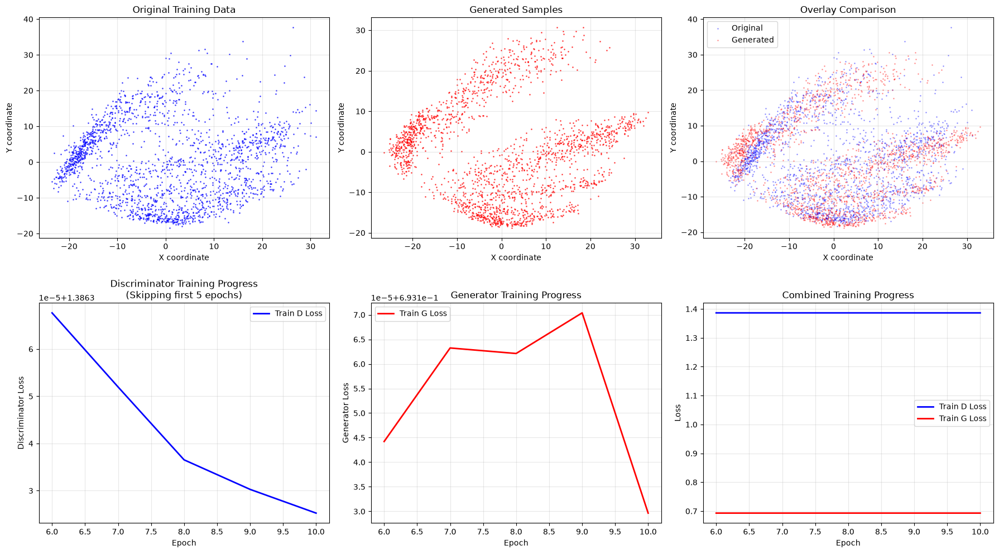

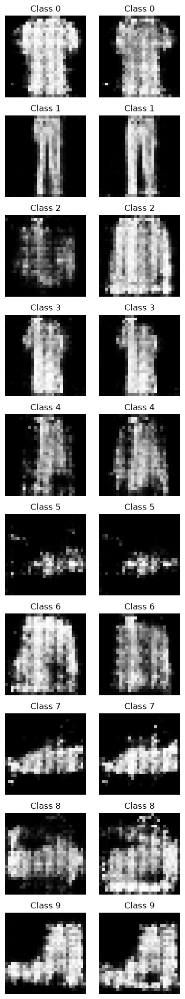

📈 Epoch 10 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6912

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.386346	G_loss: 0.695177
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.386333	G_loss: 0.691763
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.386307	G_loss: 0.693956
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.386361	G_loss: 0.693358
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.386412	G_loss: 0.694387
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.386283	G_loss: 0.692114
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.386293	G_loss: 0.692591
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.386310	G_loss: 0.690529
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.386368	G_loss: 0.694442
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.386404	G_loss: 0.695711
====> Epoch: 11 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 11 Val D_loss: 1.3862, Val G_loss: 0.6945
📈 Epoch 11 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932

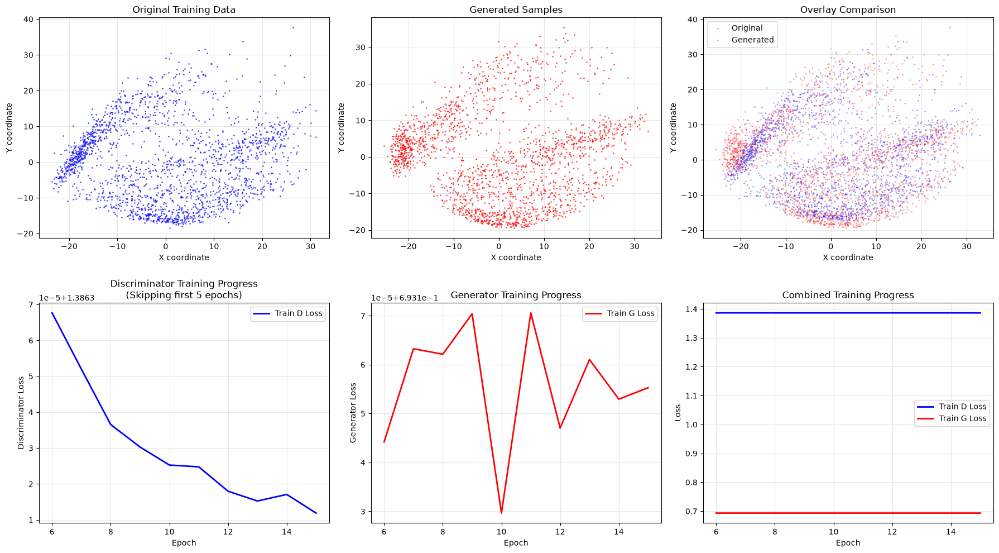

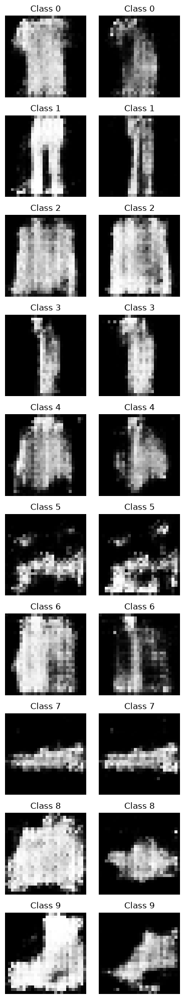

📈 Epoch 15 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6948

📊 Epoch 16/200
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.386307	G_loss: 0.691280
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.386301	G_loss: 0.693892
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.386306	G_loss: 0.694993
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.386317	G_loss: 0.691805
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.386315	G_loss: 0.691104
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.386307	G_loss: 0.692015
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.386309	G_loss: 0.692601
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.386300	G_loss: 0.692332
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.386314	G_loss: 0.691509
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.386308	G_loss: 0.690952
====> Epoch: 16 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 16 Val D_loss: 1.3863, Val G_loss: 0.6929
📈 Epoch 16 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931

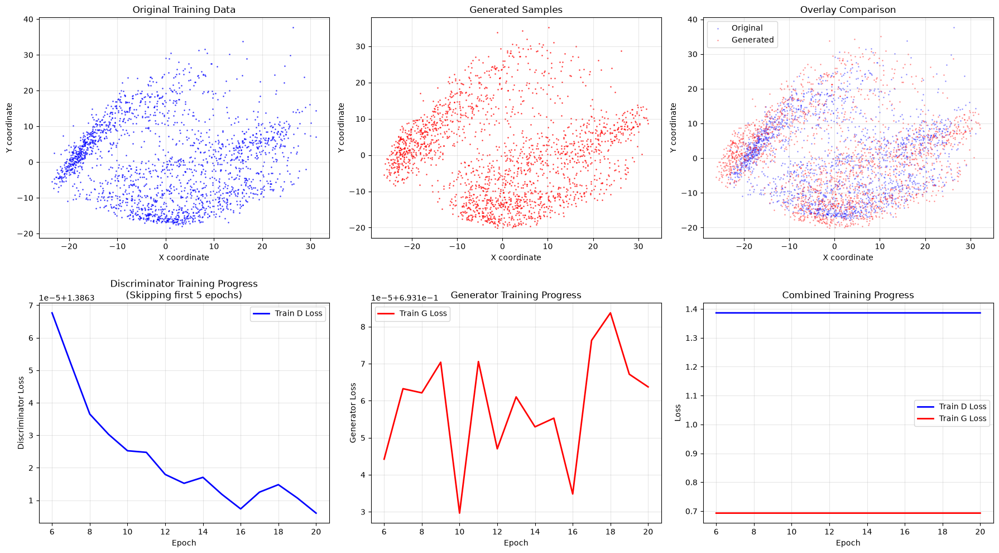

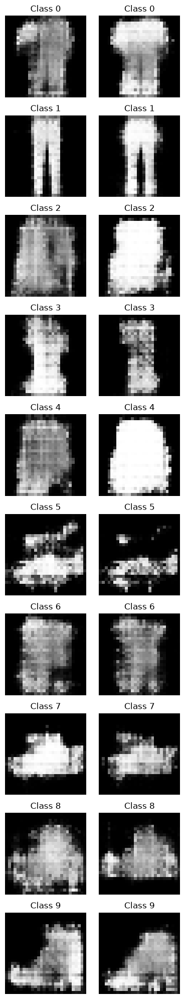

📈 Epoch 20 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6956

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.386323	G_loss: 0.691195
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.386361	G_loss: 0.692264
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.386329	G_loss: 0.693084
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.386354	G_loss: 0.692639
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.386340	G_loss: 0.693981
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.386280	G_loss: 0.692156
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.386230	G_loss: 0.692849
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.386238	G_loss: 0.693421
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.386280	G_loss: 0.693415
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.386304	G_loss: 0.693118
====> Epoch: 21 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 21 Val D_loss: 1.3865, Val G_loss: 0.6945
📈 Epoch 21 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train G Loss: 0.6932

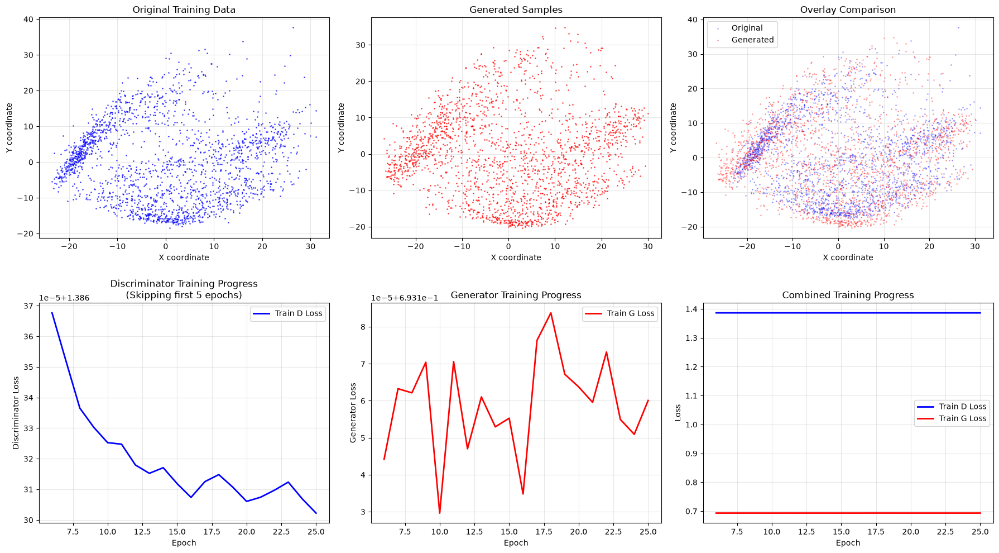

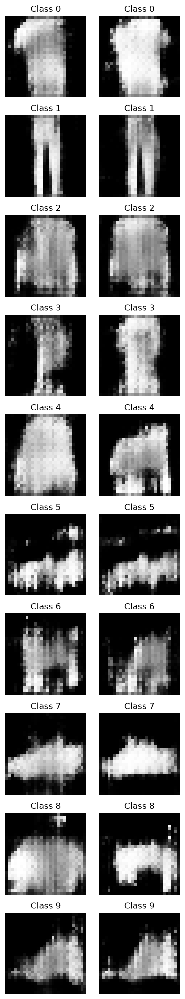

📈 Epoch 25 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6940

📊 Epoch 26/200
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.386283	G_loss: 0.692609
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.386307	G_loss: 0.692983
Epoch: 26 [12800/60000 (21%)]	D_loss: 1.386328	G_loss: 0.694780
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.386339	G_loss: 0.692489
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.386288	G_loss: 0.694214
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.386287	G_loss: 0.692689
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.386305	G_loss: 0.692703
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.386353	G_loss: 0.692809
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.386269	G_loss: 0.691990
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.386170	G_loss: 0.695194
====> Epoch: 26 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 26 Val D_loss: 1.3860, Val G_loss: 0.6929
📈 Epoch 26 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3860
   Train G Loss: 0.6932

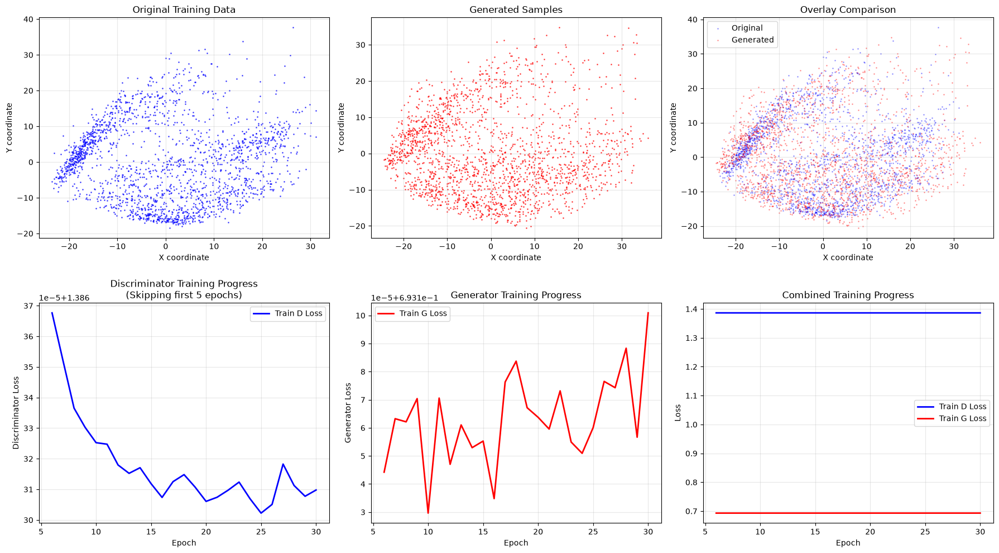

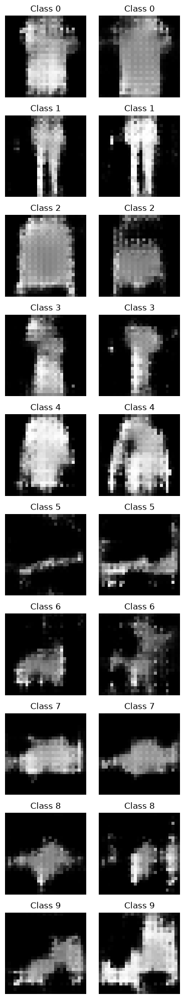

📈 Epoch 30 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6934

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.386388	G_loss: 0.693457
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.386380	G_loss: 0.692515
Epoch: 31 [12800/60000 (21%)]	D_loss: 1.386289	G_loss: 0.692815
Epoch: 31 [19200/60000 (32%)]	D_loss: 1.386201	G_loss: 0.693156
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.386323	G_loss: 0.693305
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.386279	G_loss: 0.693429
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.386407	G_loss: 0.693469
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.386317	G_loss: 0.693137
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.386375	G_loss: 0.692120
Epoch: 31 [57600/60000 (96%)]	D_loss: 1.386224	G_loss: 0.693293
====> Epoch: 31 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 31 Val D_loss: 1.3865, Val G_loss: 0.6921
📈 Epoch 31 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train G Loss: 0.6932

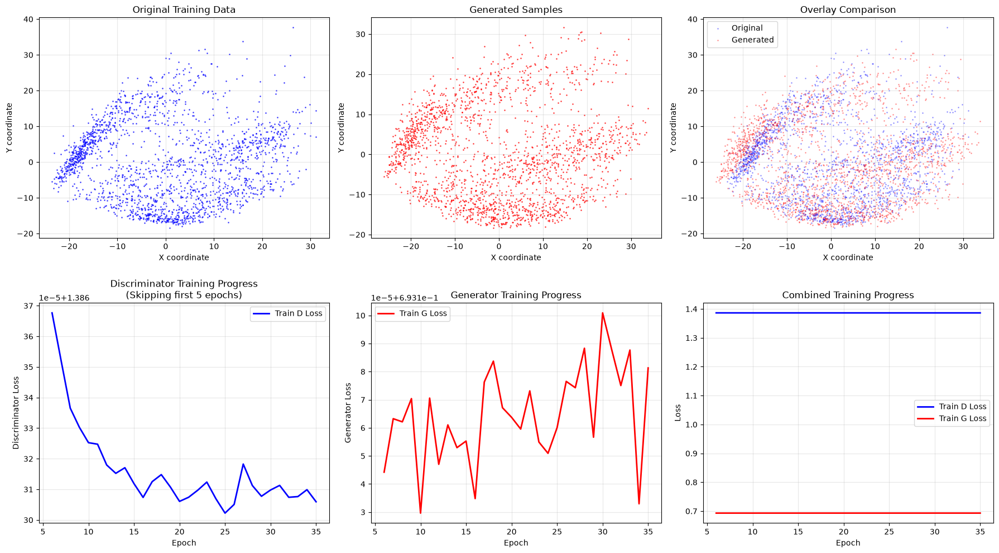

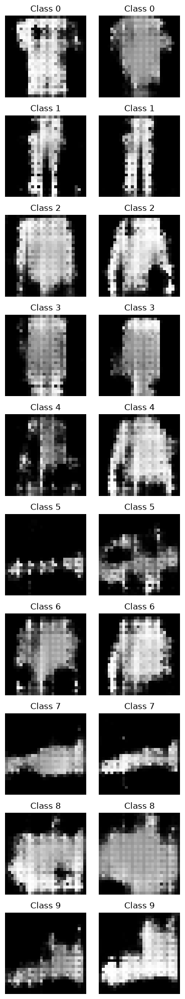

📈 Epoch 35 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6929

📊 Epoch 36/200
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 1.386241	G_loss: 0.693324
Epoch: 36 [6400/60000 (11%)]	D_loss: 1.386252	G_loss: 0.694597
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.386295	G_loss: 0.692847
Epoch: 36 [19200/60000 (32%)]	D_loss: 1.386227	G_loss: 0.695008
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.385991	G_loss: 0.693720
Epoch: 36 [32000/60000 (53%)]	D_loss: 1.386361	G_loss: 0.692043
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.386219	G_loss: 0.691444
Epoch: 36 [44800/60000 (75%)]	D_loss: 1.386350	G_loss: 0.693149
Epoch: 36 [51200/60000 (85%)]	D_loss: 1.386308	G_loss: 0.692522
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.386460	G_loss: 0.692303
====> Epoch: 36 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 36 Val D_loss: 1.3863, Val G_loss: 0.6926
📈 Epoch 36 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932

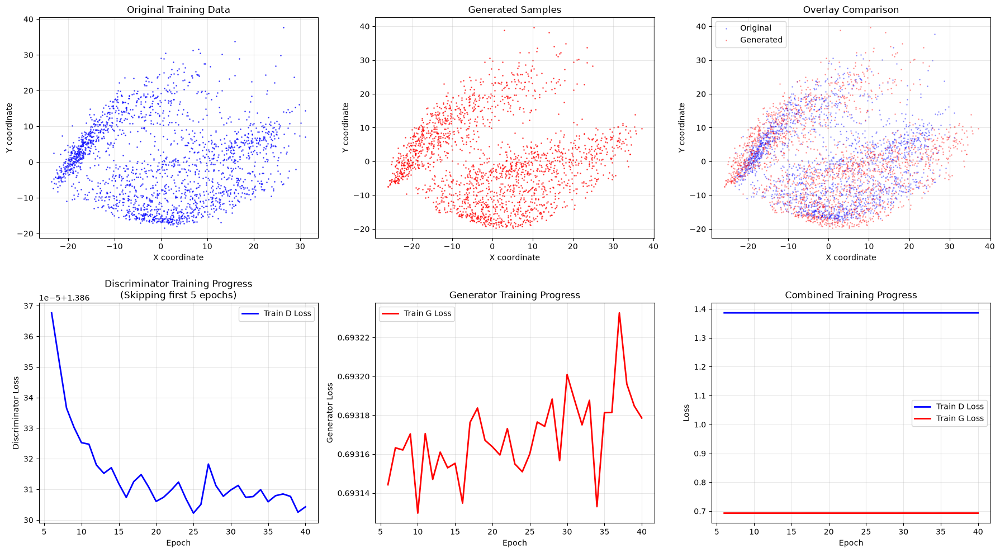

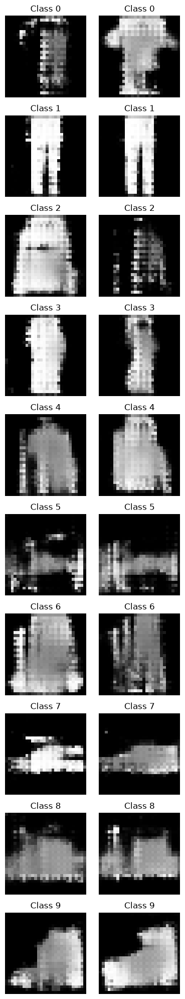

📈 Epoch 40 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6935

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 1.386283	G_loss: 0.692445
Epoch: 41 [6400/60000 (11%)]	D_loss: 1.386259	G_loss: 0.693429
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.386236	G_loss: 0.692542
Epoch: 41 [19200/60000 (32%)]	D_loss: 1.386256	G_loss: 0.693042
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.386185	G_loss: 0.693313
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.386356	G_loss: 0.692417
Epoch: 41 [38400/60000 (64%)]	D_loss: 1.386289	G_loss: 0.692876
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.386335	G_loss: 0.693094
Epoch: 41 [51200/60000 (85%)]	D_loss: 1.386330	G_loss: 0.692238
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.386271	G_loss: 0.692715
====> Epoch: 41 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 41 Val D_loss: 1.3863, Val G_loss: 0.6933
📈 Epoch 41 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932

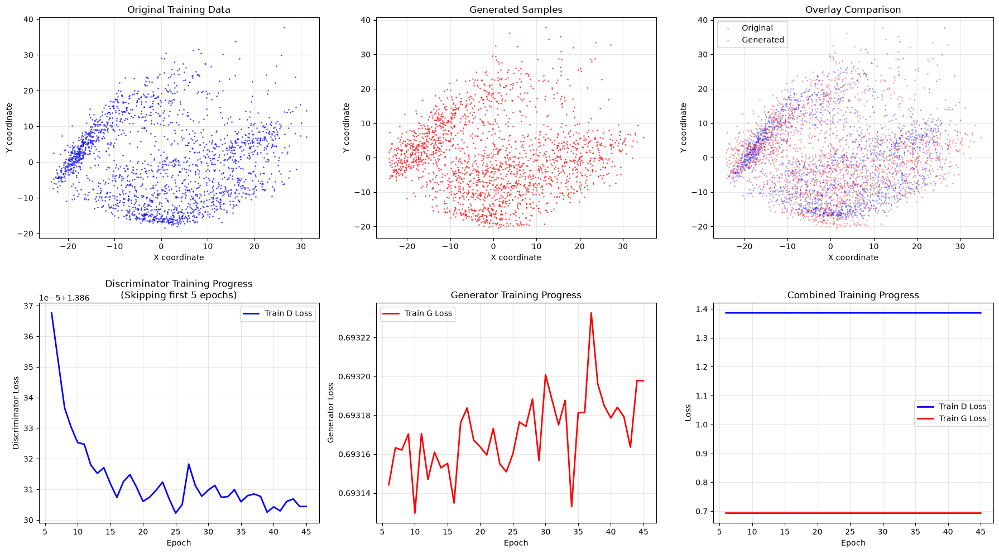

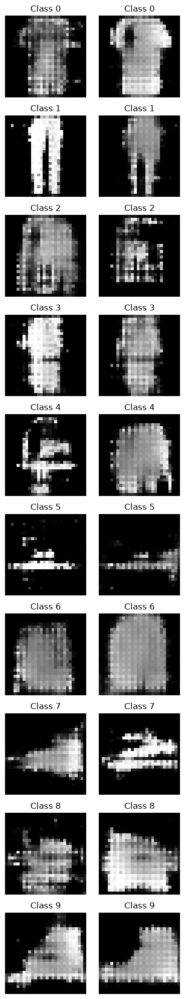

📈 Epoch 45 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3856
   Train G Loss: 0.6932, Val G Loss: 0.6945

📊 Epoch 46/200
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.386170	G_loss: 0.691616
Epoch: 46 [6400/60000 (11%)]	D_loss: 1.386267	G_loss: 0.693532
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.386285	G_loss: 0.694770
Epoch: 46 [19200/60000 (32%)]	D_loss: 1.386278	G_loss: 0.694503
Epoch: 46 [25600/60000 (43%)]	D_loss: 1.386337	G_loss: 0.692180
Epoch: 46 [32000/60000 (53%)]	D_loss: 1.386246	G_loss: 0.691939
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.386075	G_loss: 0.694293
Epoch: 46 [44800/60000 (75%)]	D_loss: 1.386291	G_loss: 0.693255
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.386175	G_loss: 0.693693
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.386424	G_loss: 0.694723
====> Epoch: 46 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 46 Val D_loss: 1.3863, Val G_loss: 0.6943
📈 Epoch 46 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6933

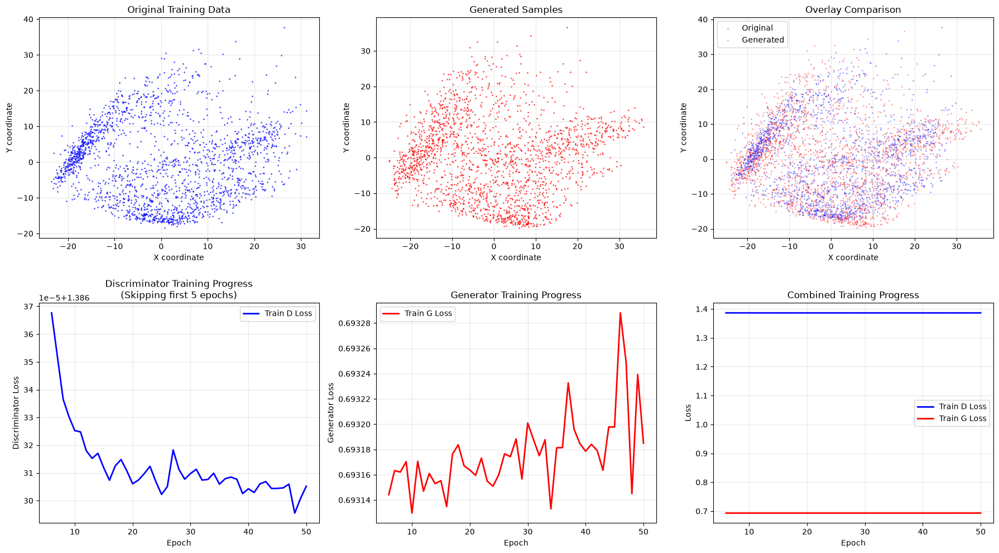

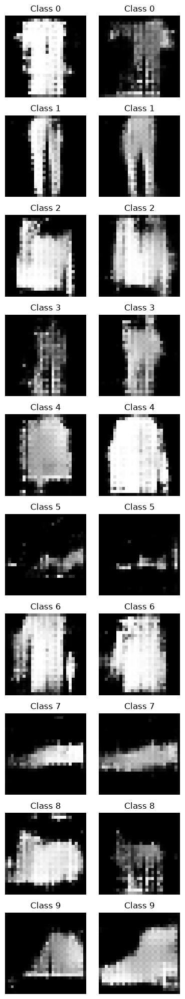

📈 Epoch 50 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6929

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 1.386261	G_loss: 0.693787
Epoch: 51 [6400/60000 (11%)]	D_loss: 1.386165	G_loss: 0.693151
Epoch: 51 [12800/60000 (21%)]	D_loss: 1.386265	G_loss: 0.692925
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.386299	G_loss: 0.693555
Epoch: 51 [25600/60000 (43%)]	D_loss: 1.386438	G_loss: 0.692168
Epoch: 51 [32000/60000 (53%)]	D_loss: 1.386446	G_loss: 0.691745
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.386381	G_loss: 0.692908
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.386401	G_loss: 0.693284
Epoch: 51 [51200/60000 (85%)]	D_loss: 1.386131	G_loss: 0.693013
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.386245	G_loss: 0.691109
====> Epoch: 51 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 51 Val D_loss: 1.3862, Val G_loss: 0.6932
📈 Epoch 51 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932

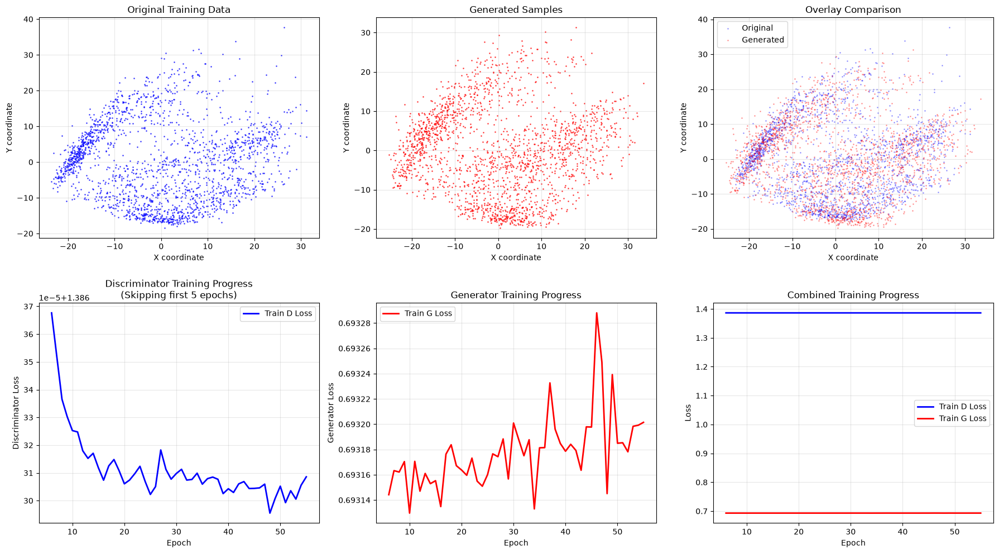

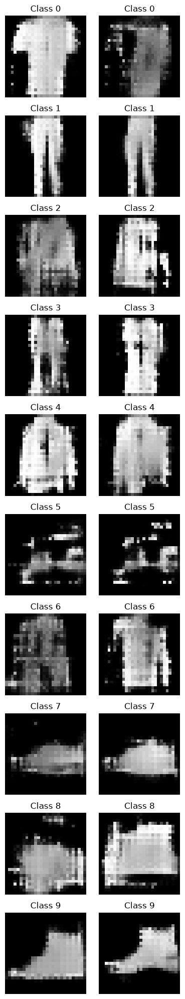

📈 Epoch 55 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train G Loss: 0.6932, Val G Loss: 0.6935

📊 Epoch 56/200
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.386118	G_loss: 0.691633
Epoch: 56 [6400/60000 (11%)]	D_loss: 1.386228	G_loss: 0.692638
Epoch: 56 [12800/60000 (21%)]	D_loss: 1.386361	G_loss: 0.693220
Epoch: 56 [19200/60000 (32%)]	D_loss: 1.386237	G_loss: 0.693593
Epoch: 56 [25600/60000 (43%)]	D_loss: 1.386494	G_loss: 0.693317
Epoch: 56 [32000/60000 (53%)]	D_loss: 1.386500	G_loss: 0.694007
Epoch: 56 [38400/60000 (64%)]	D_loss: 1.386225	G_loss: 0.693180
Epoch: 56 [44800/60000 (75%)]	D_loss: 1.386171	G_loss: 0.692904
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.386291	G_loss: 0.695075
Epoch: 56 [57600/60000 (96%)]	D_loss: 1.386124	G_loss: 0.693461
====> Epoch: 56 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 56 Val D_loss: 1.3863, Val G_loss: 0.6935
📈 Epoch 56 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932

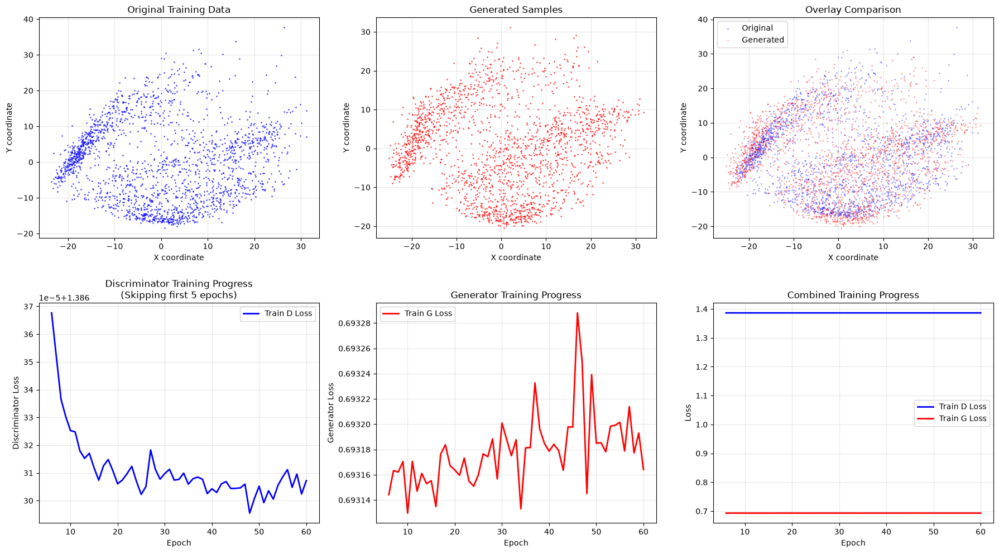

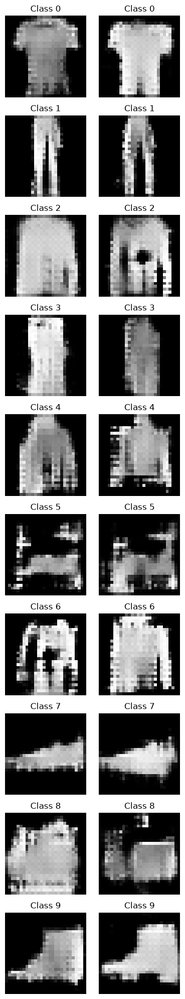

📈 Epoch 60 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6941

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 1.386302	G_loss: 0.692150
Epoch: 61 [6400/60000 (11%)]	D_loss: 1.386353	G_loss: 0.692801
Epoch: 61 [12800/60000 (21%)]	D_loss: 1.386334	G_loss: 0.693378
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.386374	G_loss: 0.693282
Epoch: 61 [25600/60000 (43%)]	D_loss: 1.386338	G_loss: 0.692357
Epoch: 61 [32000/60000 (53%)]	D_loss: 1.386534	G_loss: 0.692170
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.386303	G_loss: 0.694425
Epoch: 61 [44800/60000 (75%)]	D_loss: 1.386232	G_loss: 0.694995
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.386209	G_loss: 0.693610
Epoch: 61 [57600/60000 (96%)]	D_loss: 1.386319	G_loss: 0.692136
====> Epoch: 61 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 61 Val D_loss: 1.3861, Val G_loss: 0.6925
📈 Epoch 61 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932

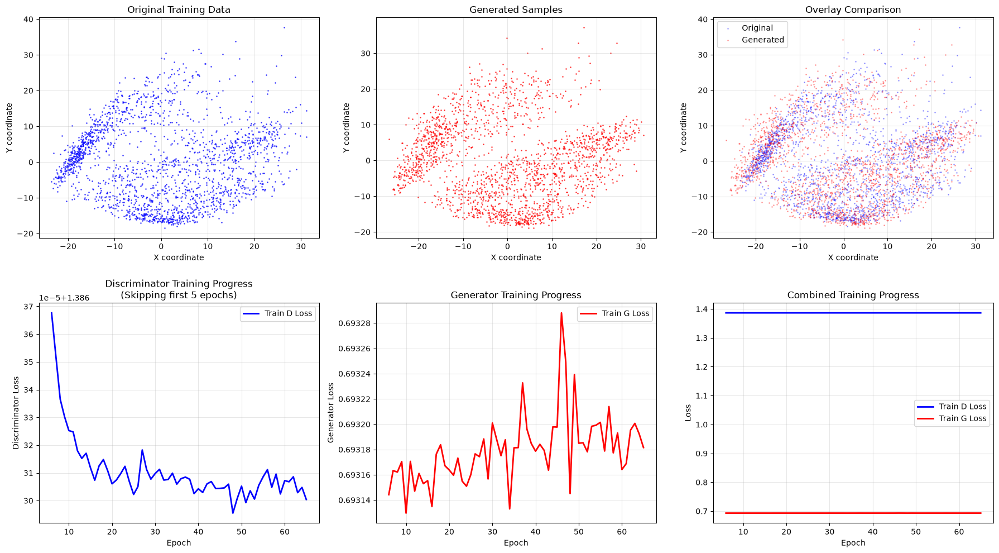

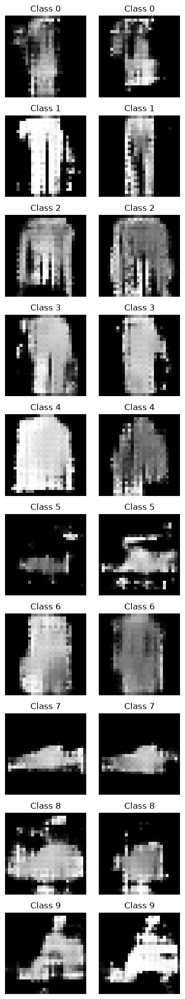

📈 Epoch 65 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train G Loss: 0.6932, Val G Loss: 0.6938

📊 Epoch 66/200
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.386283	G_loss: 0.692979
Epoch: 66 [6400/60000 (11%)]	D_loss: 1.386287	G_loss: 0.692242
Epoch: 66 [12800/60000 (21%)]	D_loss: 1.386312	G_loss: 0.693277
Epoch: 66 [19200/60000 (32%)]	D_loss: 1.386270	G_loss: 0.694190
Epoch: 66 [25600/60000 (43%)]	D_loss: 1.386256	G_loss: 0.694319
Epoch: 66 [32000/60000 (53%)]	D_loss: 1.386507	G_loss: 0.693010
Epoch: 66 [38400/60000 (64%)]	D_loss: 1.386169	G_loss: 0.694326
Epoch: 66 [44800/60000 (75%)]	D_loss: 1.386353	G_loss: 0.692778
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.386198	G_loss: 0.693084
Epoch: 66 [57600/60000 (96%)]	D_loss: 1.386180	G_loss: 0.692928
====> Epoch: 66 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 66 Val D_loss: 1.3862, Val G_loss: 0.6937
📈 Epoch 66 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932

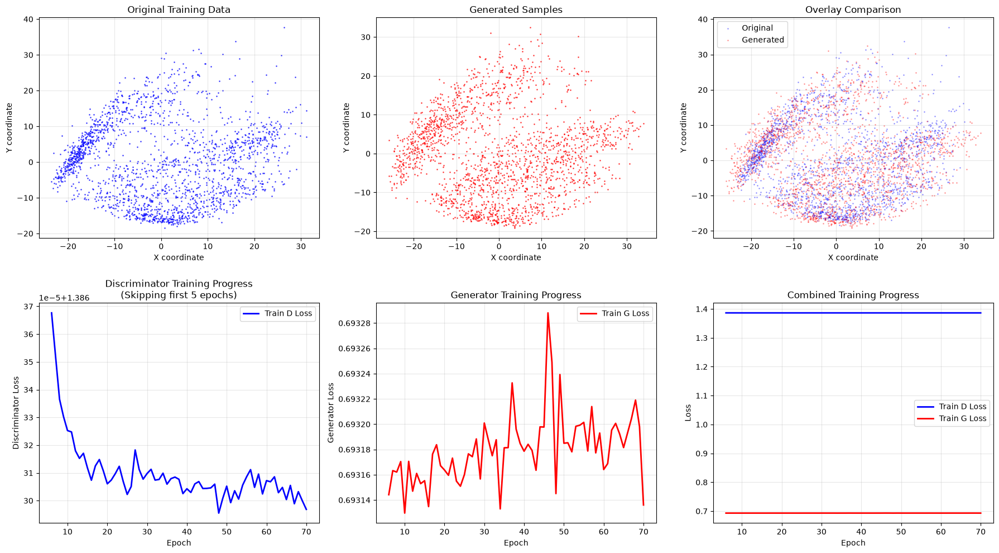

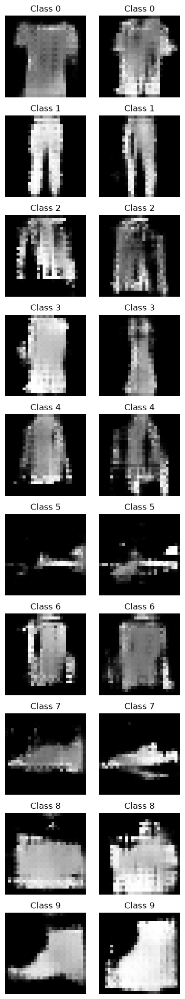

📈 Epoch 70 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6931, Val G Loss: 0.6947

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 1.386524	G_loss: 0.692664
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.386085	G_loss: 0.692218
Epoch: 71 [12800/60000 (21%)]	D_loss: 1.386375	G_loss: 0.693833
Epoch: 71 [19200/60000 (32%)]	D_loss: 1.386275	G_loss: 0.691102
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.386278	G_loss: 0.693096
Epoch: 71 [32000/60000 (53%)]	D_loss: 1.386194	G_loss: 0.692764
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.386389	G_loss: 0.693133
Epoch: 71 [44800/60000 (75%)]	D_loss: 1.386372	G_loss: 0.692881
Epoch: 71 [51200/60000 (85%)]	D_loss: 1.386291	G_loss: 0.690277
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.386141	G_loss: 0.695219
====> Epoch: 71 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 71 Val D_loss: 1.3856, Val G_loss: 0.6908
📈 Epoch 71 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3856
   Train G Loss: 0.6932

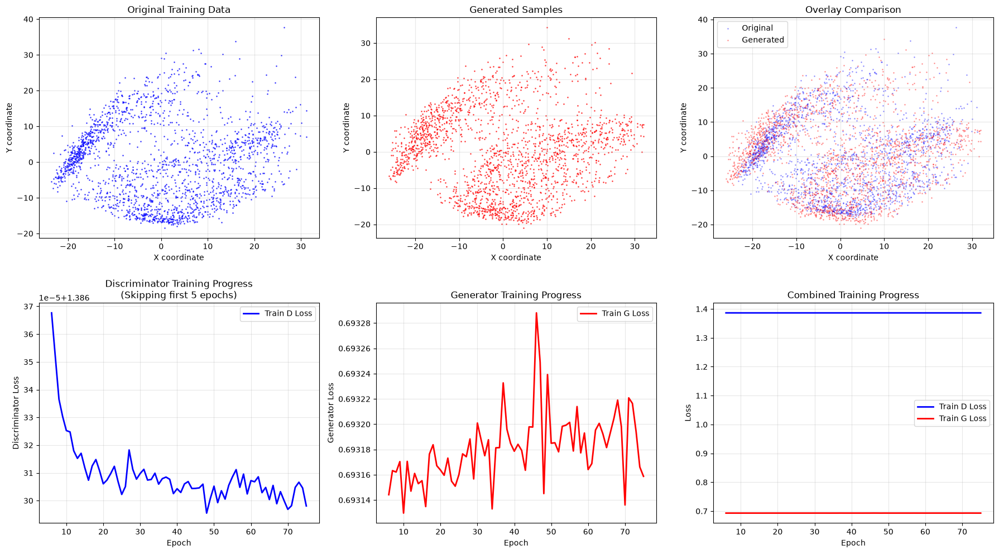

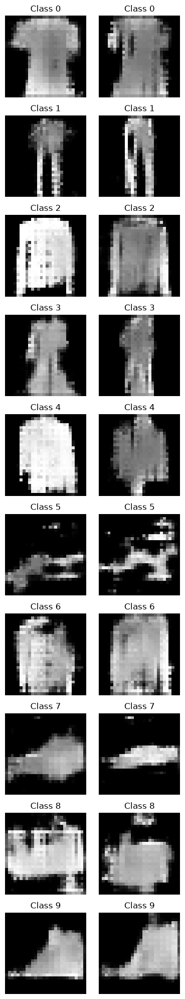

📈 Epoch 75 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6946

📊 Epoch 76/200
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.386399	G_loss: 0.694494
Epoch: 76 [6400/60000 (11%)]	D_loss: 1.386195	G_loss: 0.692743
Epoch: 76 [12800/60000 (21%)]	D_loss: 1.386281	G_loss: 0.692852
Epoch: 76 [19200/60000 (32%)]	D_loss: 1.386419	G_loss: 0.693065
Epoch: 76 [25600/60000 (43%)]	D_loss: 1.386135	G_loss: 0.692560
Epoch: 76 [32000/60000 (53%)]	D_loss: 1.386338	G_loss: 0.692355
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.386211	G_loss: 0.694301
Epoch: 76 [44800/60000 (75%)]	D_loss: 1.386434	G_loss: 0.692828
Epoch: 76 [51200/60000 (85%)]	D_loss: 1.386045	G_loss: 0.693504
Epoch: 76 [57600/60000 (96%)]	D_loss: 1.386266	G_loss: 0.692203
====> Epoch: 76 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 76 Val D_loss: 1.3868, Val G_loss: 0.6939
📈 Epoch 76 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3868
   Train G Loss: 0.6932

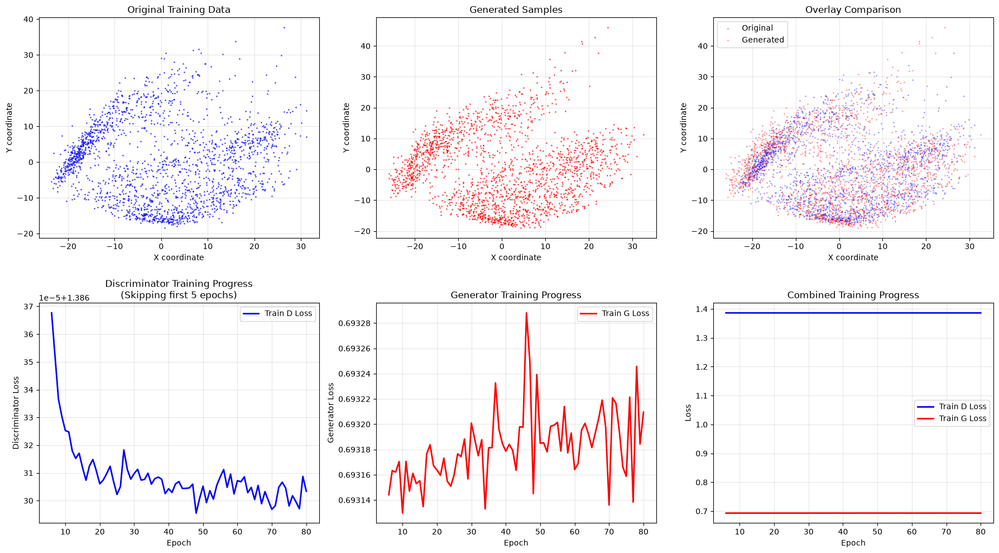

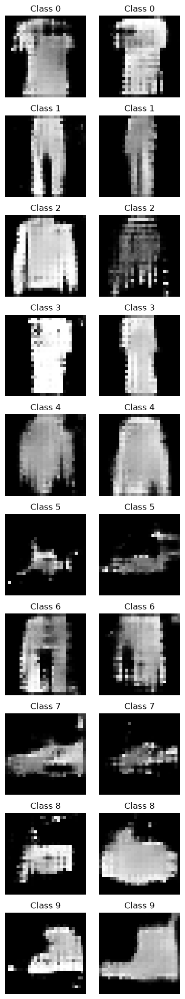

📈 Epoch 80 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6932

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 1.386317	G_loss: 0.694411
Epoch: 81 [6400/60000 (11%)]	D_loss: 1.386219	G_loss: 0.691608
Epoch: 81 [12800/60000 (21%)]	D_loss: 1.386348	G_loss: 0.692571
Epoch: 81 [19200/60000 (32%)]	D_loss: 1.386233	G_loss: 0.694547
Epoch: 81 [25600/60000 (43%)]	D_loss: 1.386247	G_loss: 0.692930
Epoch: 81 [32000/60000 (53%)]	D_loss: 1.386359	G_loss: 0.692498
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.386222	G_loss: 0.693285
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.386295	G_loss: 0.694088
Epoch: 81 [51200/60000 (85%)]	D_loss: 1.386362	G_loss: 0.692319
Epoch: 81 [57600/60000 (96%)]	D_loss: 1.386361	G_loss: 0.691423
====> Epoch: 81 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 81 Val D_loss: 1.3862, Val G_loss: 0.6908
📈 Epoch 81 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6931

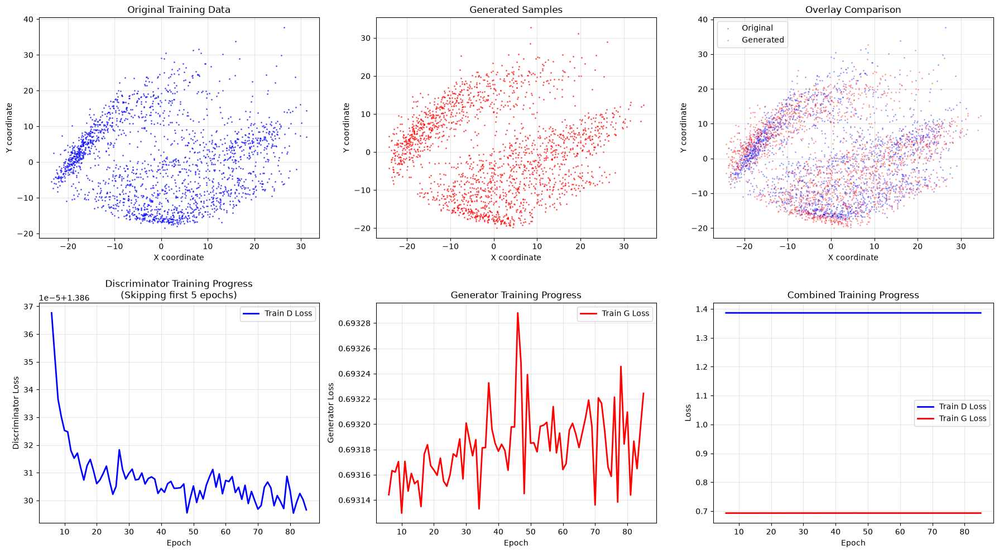

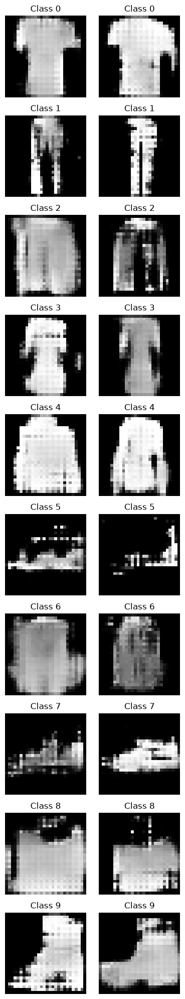

📈 Epoch 85 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932, Val G Loss: 0.6941

📊 Epoch 86/200
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 1.386554	G_loss: 0.692830
Epoch: 86 [6400/60000 (11%)]	D_loss: 1.386079	G_loss: 0.693881
Epoch: 86 [12800/60000 (21%)]	D_loss: 1.386364	G_loss: 0.693389
Epoch: 86 [19200/60000 (32%)]	D_loss: 1.386317	G_loss: 0.692788
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.386150	G_loss: 0.692706
Epoch: 86 [32000/60000 (53%)]	D_loss: 1.386394	G_loss: 0.694076
Epoch: 86 [38400/60000 (64%)]	D_loss: 1.386167	G_loss: 0.692934
Epoch: 86 [44800/60000 (75%)]	D_loss: 1.386514	G_loss: 0.691663
Epoch: 86 [51200/60000 (85%)]	D_loss: 1.386426	G_loss: 0.693579
Epoch: 86 [57600/60000 (96%)]	D_loss: 1.386339	G_loss: 0.693523
====> Epoch: 86 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 86 Val D_loss: 1.3860, Val G_loss: 0.6933
📈 Epoch 86 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3860
   Train G Loss: 0.6932

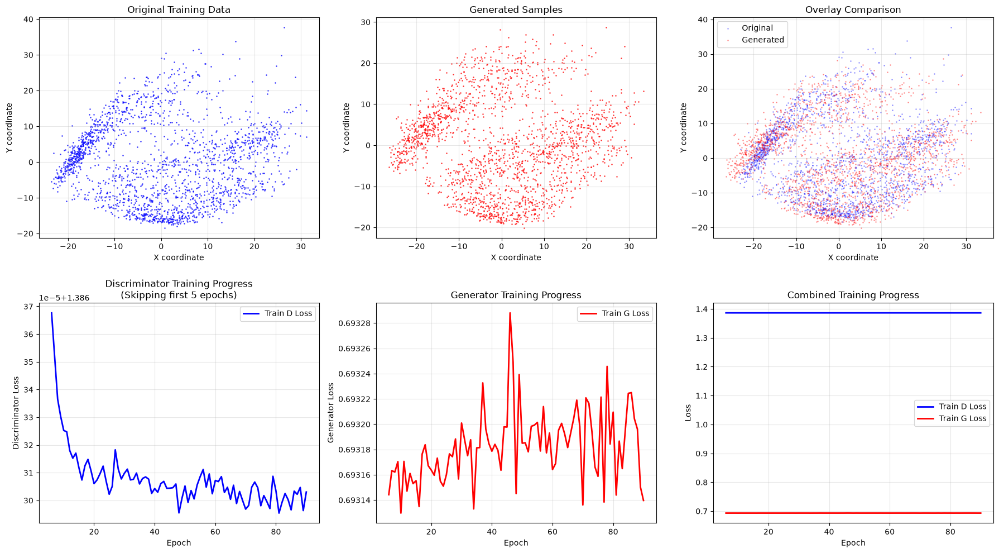

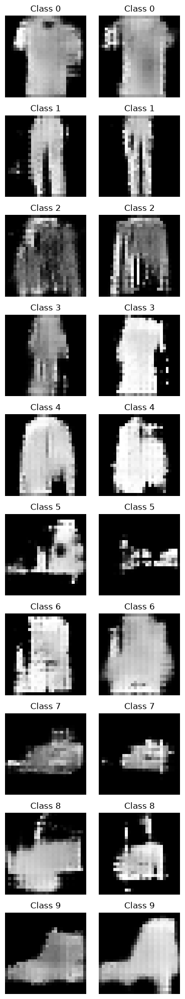

📈 Epoch 90 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6925

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 1.386170	G_loss: 0.692653
Epoch: 91 [6400/60000 (11%)]	D_loss: 1.386272	G_loss: 0.693390
Epoch: 91 [12800/60000 (21%)]	D_loss: 1.386273	G_loss: 0.693794
Epoch: 91 [19200/60000 (32%)]	D_loss: 1.386303	G_loss: 0.693587
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.386056	G_loss: 0.691314
Epoch: 91 [32000/60000 (53%)]	D_loss: 1.386343	G_loss: 0.692866
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.386262	G_loss: 0.692747
Epoch: 91 [44800/60000 (75%)]	D_loss: 1.386236	G_loss: 0.693308
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.386177	G_loss: 0.693555
Epoch: 91 [57600/60000 (96%)]	D_loss: 1.386220	G_loss: 0.694307
====> Epoch: 91 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 91 Val D_loss: 1.3861, Val G_loss: 0.6941
📈 Epoch 91 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932

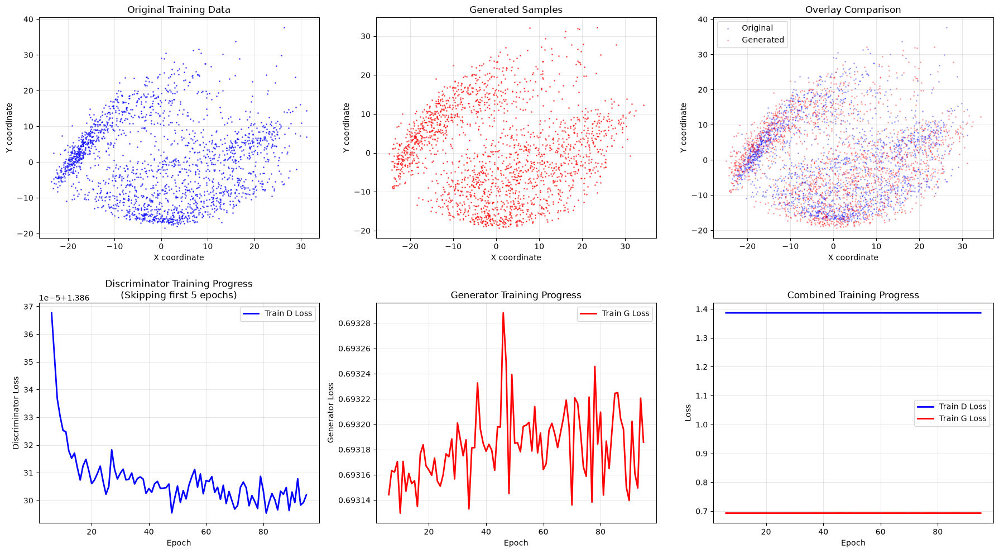

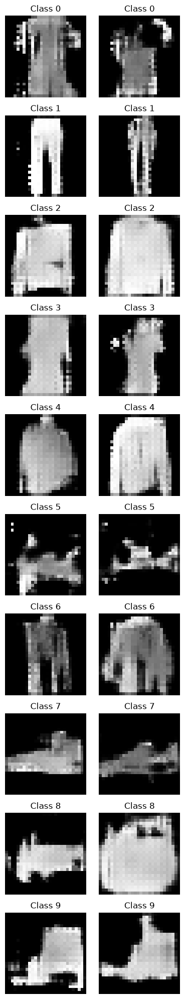

📈 Epoch 95 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6925

📊 Epoch 96/200
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 1.386279	G_loss: 0.693291
Epoch: 96 [6400/60000 (11%)]	D_loss: 1.386210	G_loss: 0.694387
Epoch: 96 [12800/60000 (21%)]	D_loss: 1.386343	G_loss: 0.693442
Epoch: 96 [19200/60000 (32%)]	D_loss: 1.386258	G_loss: 0.692192
Epoch: 96 [25600/60000 (43%)]	D_loss: 1.386371	G_loss: 0.693084
Epoch: 96 [32000/60000 (53%)]	D_loss: 1.386360	G_loss: 0.692893
Epoch: 96 [38400/60000 (64%)]	D_loss: 1.386264	G_loss: 0.693452
Epoch: 96 [44800/60000 (75%)]	D_loss: 1.386302	G_loss: 0.692839
Epoch: 96 [51200/60000 (85%)]	D_loss: 1.386374	G_loss: 0.692420
Epoch: 96 [57600/60000 (96%)]	D_loss: 1.386289	G_loss: 0.694510
====> Epoch: 96 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 96 Val D_loss: 1.3861, Val G_loss: 0.6938
📈 Epoch 96 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932

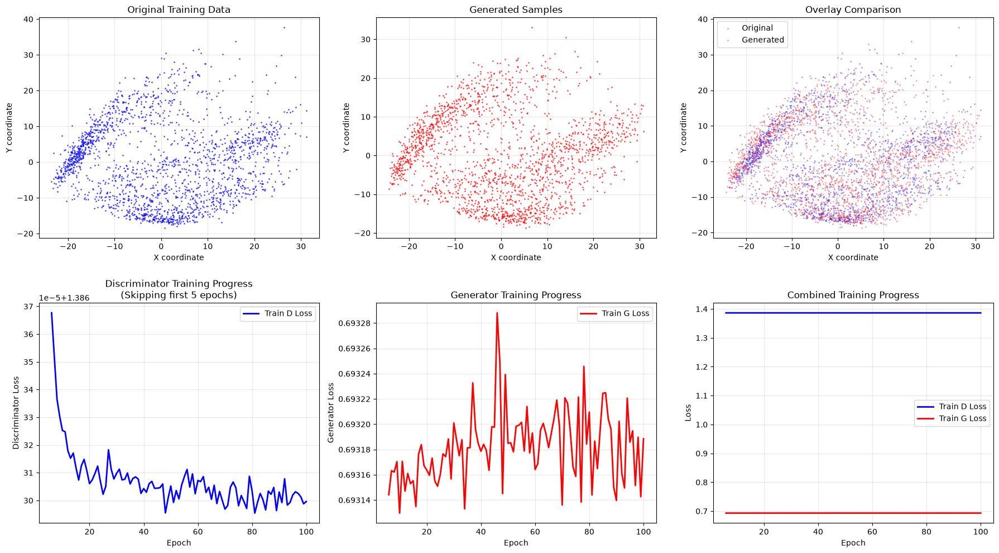

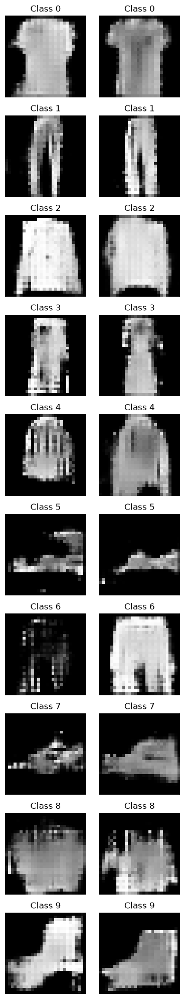

📈 Epoch 100 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6936

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	D_loss: 1.386326	G_loss: 0.694205
Epoch: 101 [6400/60000 (11%)]	D_loss: 1.386331	G_loss: 0.692074
Epoch: 101 [12800/60000 (21%)]	D_loss: 1.386322	G_loss: 0.692055
Epoch: 101 [19200/60000 (32%)]	D_loss: 1.386406	G_loss: 0.694889
Epoch: 101 [25600/60000 (43%)]	D_loss: 1.386417	G_loss: 0.691855
Epoch: 101 [32000/60000 (53%)]	D_loss: 1.386165	G_loss: 0.694815
Epoch: 101 [38400/60000 (64%)]	D_loss: 1.386295	G_loss: 0.691015
Epoch: 101 [44800/60000 (75%)]	D_loss: 1.386188	G_loss: 0.694400
Epoch: 101 [51200/60000 (85%)]	D_loss: 1.386076	G_loss: 0.692819
Epoch: 101 [57600/60000 (96%)]	D_loss: 1.386227	G_loss: 0.693253
====> Epoch: 101 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 101 Val D_loss: 1.3863, Val G_loss: 0.6921
📈 Epoch 101 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

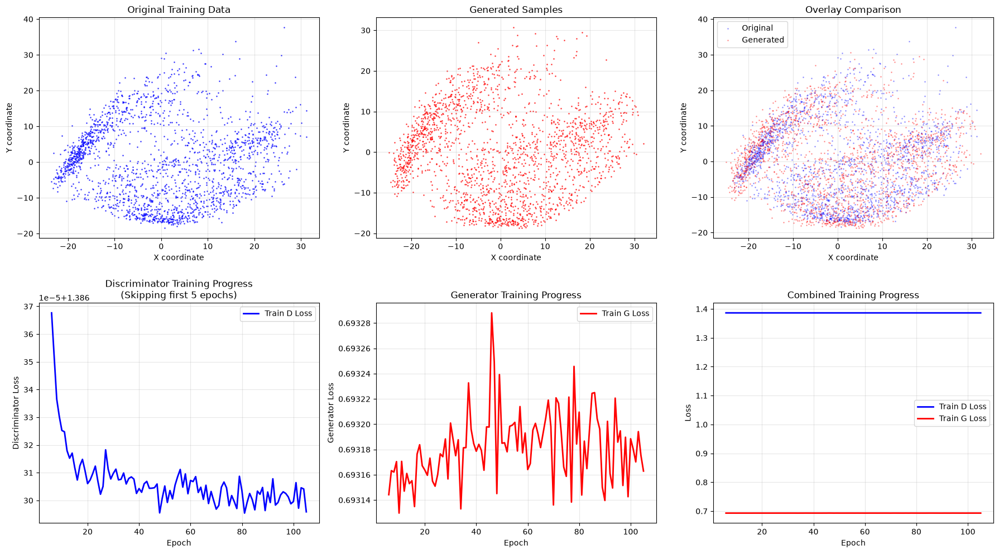

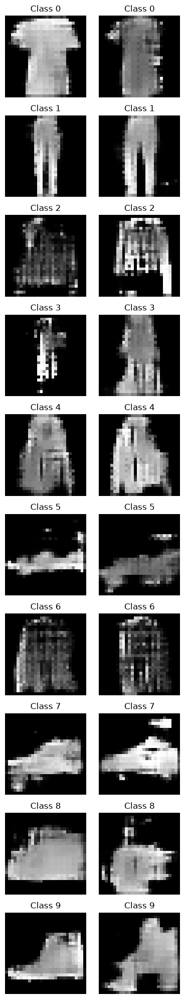

📈 Epoch 105 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6929

📊 Epoch 106/200
----------------------------------------
Epoch: 106 [0/60000 (0%)]	D_loss: 1.386354	G_loss: 0.692962
Epoch: 106 [6400/60000 (11%)]	D_loss: 1.386452	G_loss: 0.691928
Epoch: 106 [12800/60000 (21%)]	D_loss: 1.386231	G_loss: 0.692610
Epoch: 106 [19200/60000 (32%)]	D_loss: 1.386291	G_loss: 0.694175
Epoch: 106 [25600/60000 (43%)]	D_loss: 1.386364	G_loss: 0.691870
Epoch: 106 [32000/60000 (53%)]	D_loss: 1.386102	G_loss: 0.694603
Epoch: 106 [38400/60000 (64%)]	D_loss: 1.386345	G_loss: 0.693307
Epoch: 106 [44800/60000 (75%)]	D_loss: 1.386230	G_loss: 0.692934
Epoch: 106 [51200/60000 (85%)]	D_loss: 1.386443	G_loss: 0.693316
Epoch: 106 [57600/60000 (96%)]	D_loss: 1.386268	G_loss: 0.693347
====> Epoch: 106 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 106 Val D_loss: 1.3862, Val G_loss: 0.6925
📈 Epoch 106 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

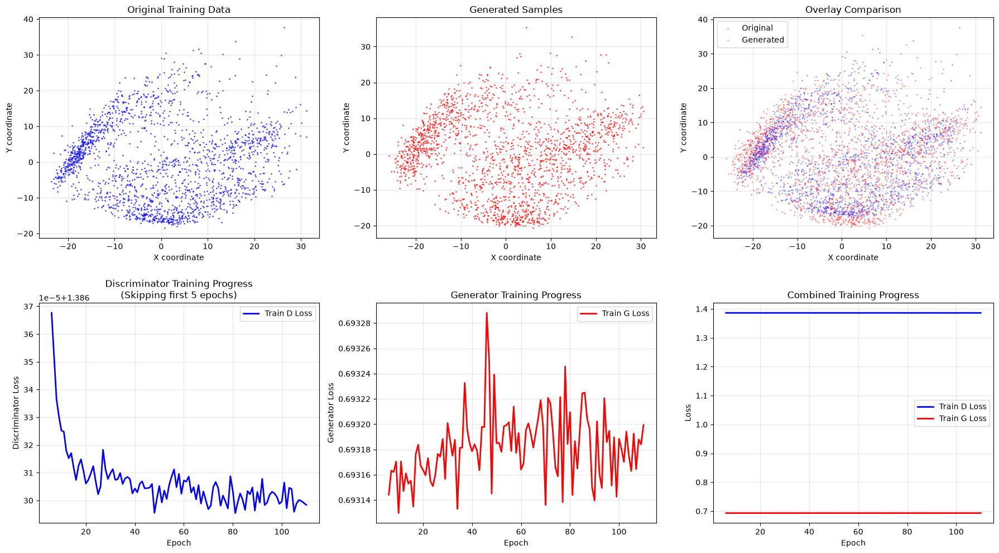

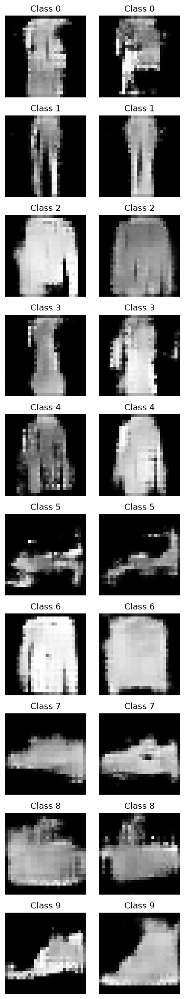

📈 Epoch 110 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3866
   Train G Loss: 0.6932, Val G Loss: 0.6925

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	D_loss: 1.386284	G_loss: 0.692186
Epoch: 111 [6400/60000 (11%)]	D_loss: 1.386345	G_loss: 0.693676
Epoch: 111 [12800/60000 (21%)]	D_loss: 1.386262	G_loss: 0.693051
Epoch: 111 [19200/60000 (32%)]	D_loss: 1.386269	G_loss: 0.693560
Epoch: 111 [25600/60000 (43%)]	D_loss: 1.386323	G_loss: 0.692166
Epoch: 111 [32000/60000 (53%)]	D_loss: 1.386332	G_loss: 0.693465
Epoch: 111 [38400/60000 (64%)]	D_loss: 1.386175	G_loss: 0.692277
Epoch: 111 [44800/60000 (75%)]	D_loss: 1.386289	G_loss: 0.692904
Epoch: 111 [51200/60000 (85%)]	D_loss: 1.386287	G_loss: 0.694367
Epoch: 111 [57600/60000 (96%)]	D_loss: 1.386256	G_loss: 0.694090
====> Epoch: 111 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 111 Val D_loss: 1.3863, Val G_loss: 0.6935
📈 Epoch 111 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

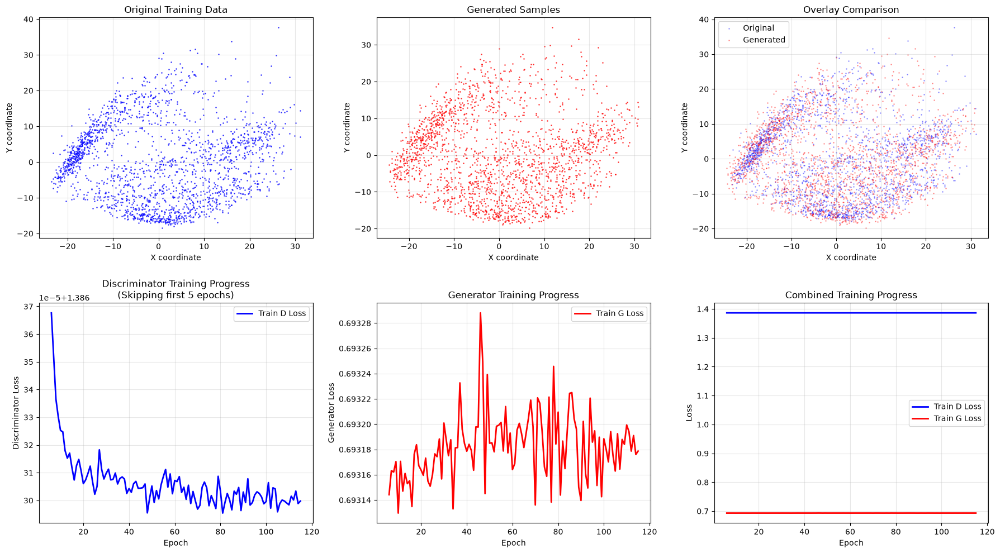

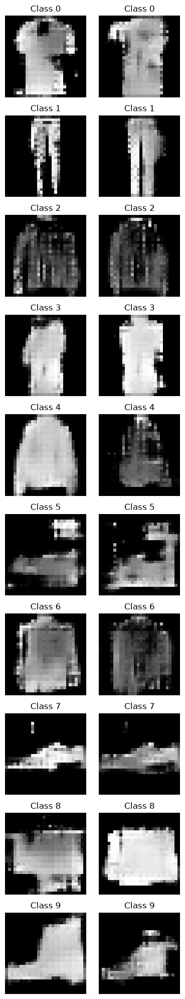

📈 Epoch 115 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6940

📊 Epoch 116/200
----------------------------------------
Epoch: 116 [0/60000 (0%)]	D_loss: 1.386269	G_loss: 0.693298
Epoch: 116 [6400/60000 (11%)]	D_loss: 1.386384	G_loss: 0.693795
Epoch: 116 [12800/60000 (21%)]	D_loss: 1.386340	G_loss: 0.694144
Epoch: 116 [19200/60000 (32%)]	D_loss: 1.386250	G_loss: 0.692195
Epoch: 116 [25600/60000 (43%)]	D_loss: 1.386334	G_loss: 0.693217
Epoch: 116 [32000/60000 (53%)]	D_loss: 1.386256	G_loss: 0.693185
Epoch: 116 [38400/60000 (64%)]	D_loss: 1.386427	G_loss: 0.693398
Epoch: 116 [44800/60000 (75%)]	D_loss: 1.386153	G_loss: 0.694009
Epoch: 116 [51200/60000 (85%)]	D_loss: 1.386395	G_loss: 0.693649
Epoch: 116 [57600/60000 (96%)]	D_loss: 1.386404	G_loss: 0.692859
====> Epoch: 116 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 116 Val D_loss: 1.3861, Val G_loss: 0.6934
📈 Epoch 116 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train

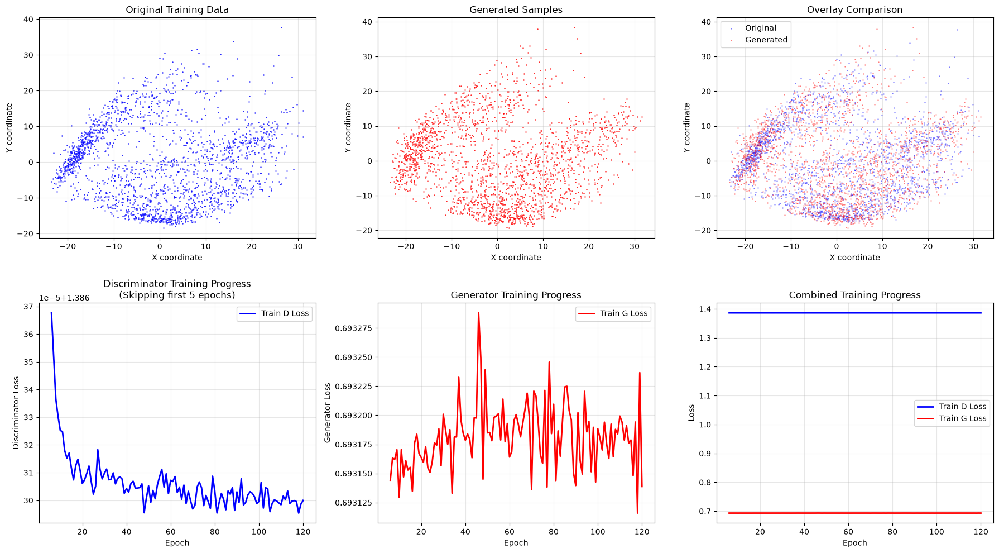

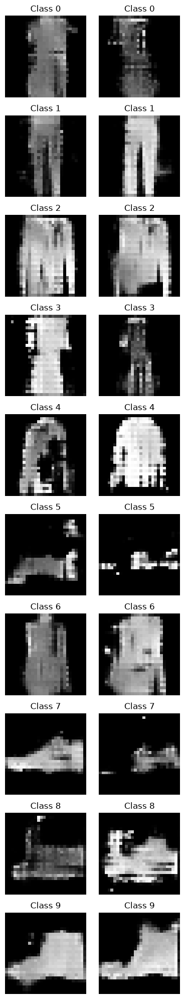

📈 Epoch 120 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6938

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	D_loss: 1.386372	G_loss: 0.694172
Epoch: 121 [6400/60000 (11%)]	D_loss: 1.386194	G_loss: 0.692871
Epoch: 121 [12800/60000 (21%)]	D_loss: 1.386322	G_loss: 0.693730
Epoch: 121 [19200/60000 (32%)]	D_loss: 1.386220	G_loss: 0.693344
Epoch: 121 [25600/60000 (43%)]	D_loss: 1.386353	G_loss: 0.692972
Epoch: 121 [32000/60000 (53%)]	D_loss: 1.386285	G_loss: 0.692474
Epoch: 121 [38400/60000 (64%)]	D_loss: 1.386330	G_loss: 0.692641
Epoch: 121 [44800/60000 (75%)]	D_loss: 1.386378	G_loss: 0.693310
Epoch: 121 [51200/60000 (85%)]	D_loss: 1.386250	G_loss: 0.694556
Epoch: 121 [57600/60000 (96%)]	D_loss: 1.386251	G_loss: 0.691666
====> Epoch: 121 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 121 Val D_loss: 1.3862, Val G_loss: 0.6933
📈 Epoch 121 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

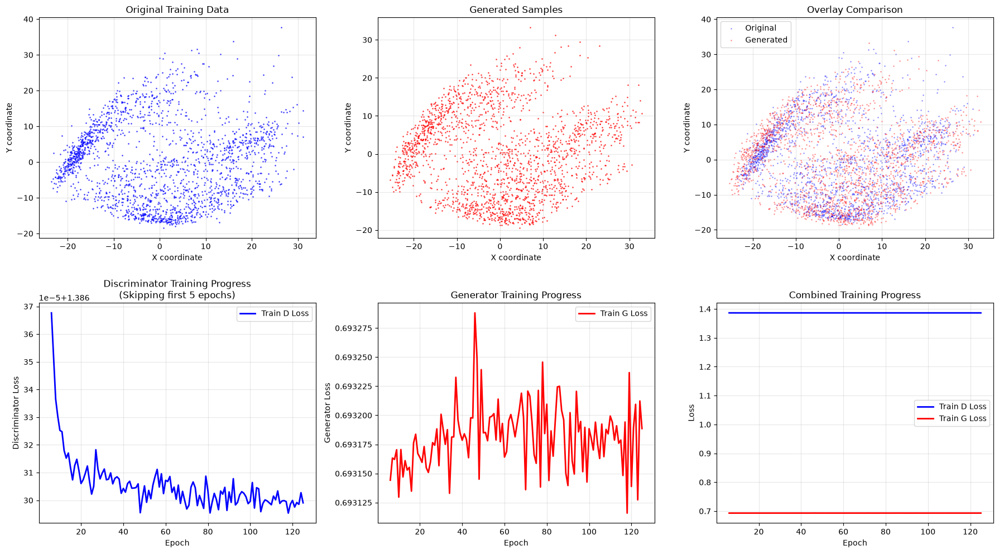

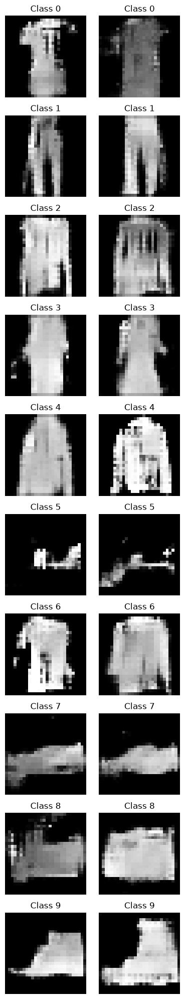

📈 Epoch 125 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6937

📊 Epoch 126/200
----------------------------------------
Epoch: 126 [0/60000 (0%)]	D_loss: 1.386389	G_loss: 0.693813
Epoch: 126 [6400/60000 (11%)]	D_loss: 1.386220	G_loss: 0.693070
Epoch: 126 [12800/60000 (21%)]	D_loss: 1.386217	G_loss: 0.694020
Epoch: 126 [19200/60000 (32%)]	D_loss: 1.386377	G_loss: 0.692676
Epoch: 126 [25600/60000 (43%)]	D_loss: 1.386184	G_loss: 0.692938
Epoch: 126 [32000/60000 (53%)]	D_loss: 1.386296	G_loss: 0.694072
Epoch: 126 [38400/60000 (64%)]	D_loss: 1.386262	G_loss: 0.692878
Epoch: 126 [44800/60000 (75%)]	D_loss: 1.386275	G_loss: 0.693101
Epoch: 126 [51200/60000 (85%)]	D_loss: 1.386246	G_loss: 0.694714
Epoch: 126 [57600/60000 (96%)]	D_loss: 1.386361	G_loss: 0.692574
====> Epoch: 126 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 126 Val D_loss: 1.3863, Val G_loss: 0.6928
📈 Epoch 126 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

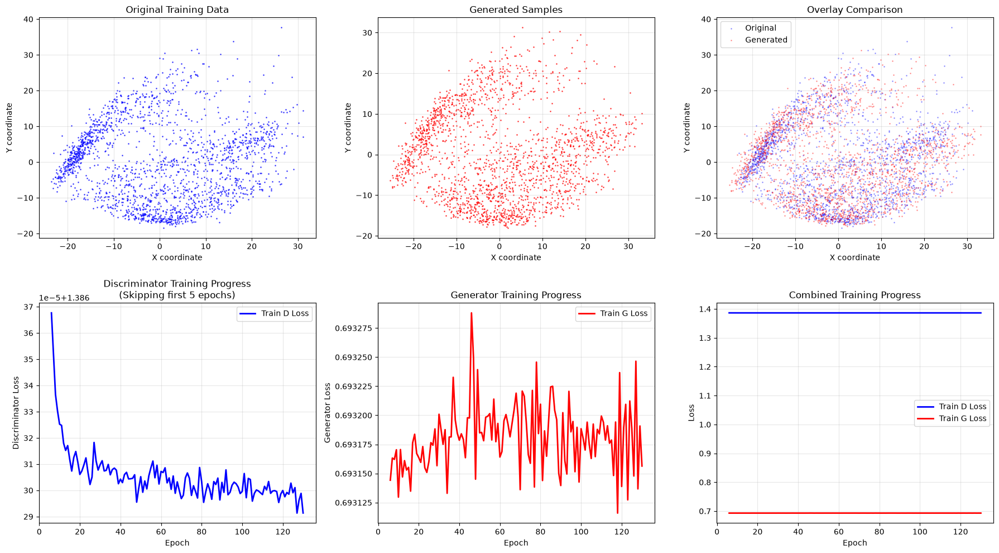

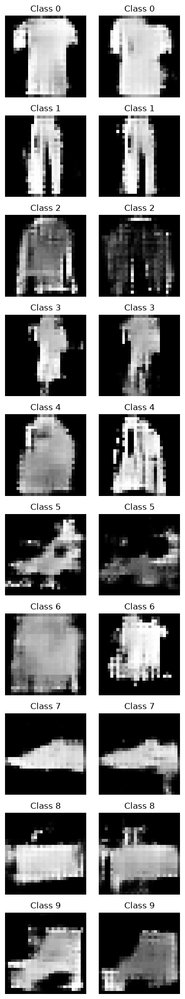

📈 Epoch 130 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3867
   Train G Loss: 0.6932, Val G Loss: 0.6925

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	D_loss: 1.386477	G_loss: 0.692979
Epoch: 131 [6400/60000 (11%)]	D_loss: 1.386259	G_loss: 0.694408
Epoch: 131 [12800/60000 (21%)]	D_loss: 1.386420	G_loss: 0.692958
Epoch: 131 [19200/60000 (32%)]	D_loss: 1.386420	G_loss: 0.693895
Epoch: 131 [25600/60000 (43%)]	D_loss: 1.386245	G_loss: 0.693737
Epoch: 131 [32000/60000 (53%)]	D_loss: 1.386258	G_loss: 0.693103
Epoch: 131 [38400/60000 (64%)]	D_loss: 1.386373	G_loss: 0.692834
Epoch: 131 [44800/60000 (75%)]	D_loss: 1.386266	G_loss: 0.693394
Epoch: 131 [51200/60000 (85%)]	D_loss: 1.386303	G_loss: 0.693381
Epoch: 131 [57600/60000 (96%)]	D_loss: 1.386357	G_loss: 0.692411
====> Epoch: 131 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 131 Val D_loss: 1.3862, Val G_loss: 0.6934
📈 Epoch 131 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

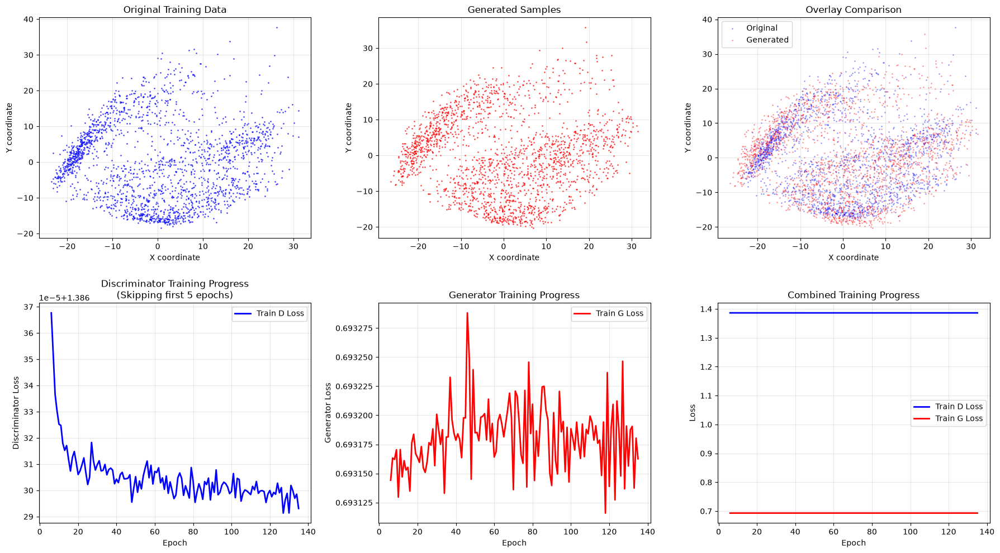

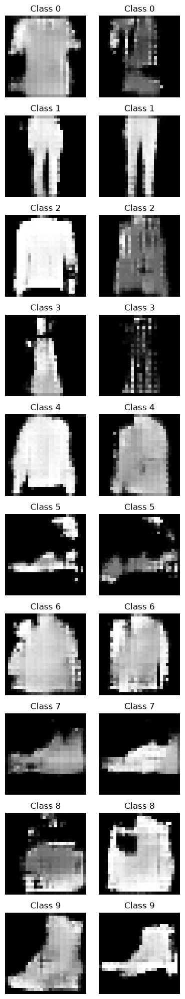

📈 Epoch 135 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6925

📊 Epoch 136/200
----------------------------------------
Epoch: 136 [0/60000 (0%)]	D_loss: 1.386224	G_loss: 0.693351
Epoch: 136 [6400/60000 (11%)]	D_loss: 1.386358	G_loss: 0.693012
Epoch: 136 [12800/60000 (21%)]	D_loss: 1.386228	G_loss: 0.693705
Epoch: 136 [19200/60000 (32%)]	D_loss: 1.386223	G_loss: 0.692287
Epoch: 136 [25600/60000 (43%)]	D_loss: 1.386224	G_loss: 0.693413
Epoch: 136 [32000/60000 (53%)]	D_loss: 1.386411	G_loss: 0.693259
Epoch: 136 [38400/60000 (64%)]	D_loss: 1.386266	G_loss: 0.694051
Epoch: 136 [44800/60000 (75%)]	D_loss: 1.386266	G_loss: 0.692822
Epoch: 136 [51200/60000 (85%)]	D_loss: 1.386123	G_loss: 0.692159
Epoch: 136 [57600/60000 (96%)]	D_loss: 1.386183	G_loss: 0.692783
====> Epoch: 136 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 136 Val D_loss: 1.3865, Val G_loss: 0.6933
📈 Epoch 136 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train

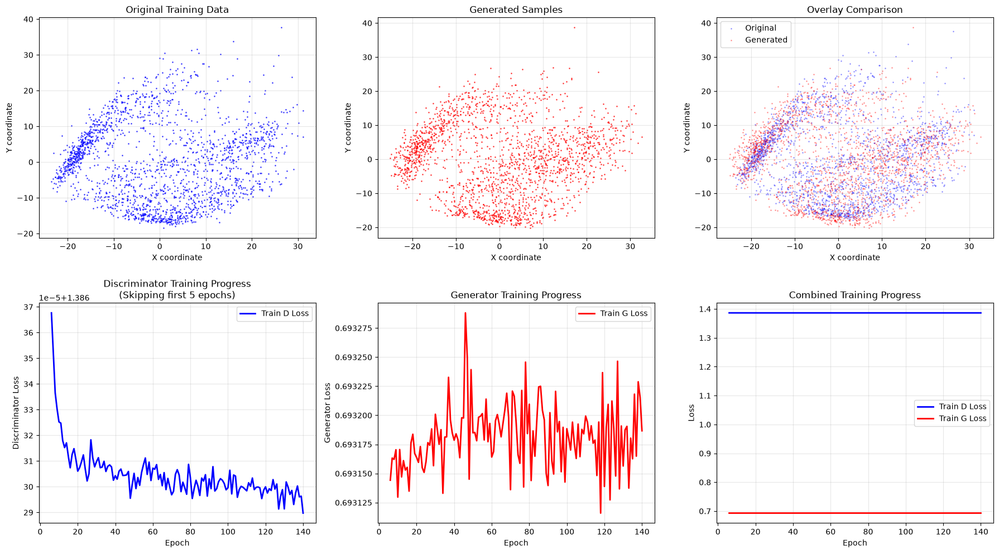

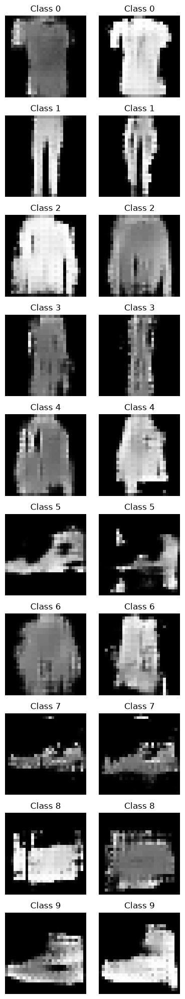

📈 Epoch 140 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6919

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	D_loss: 1.386239	G_loss: 0.691738
Epoch: 141 [6400/60000 (11%)]	D_loss: 1.386284	G_loss: 0.693658
Epoch: 141 [12800/60000 (21%)]	D_loss: 1.386358	G_loss: 0.693241
Epoch: 141 [19200/60000 (32%)]	D_loss: 1.386368	G_loss: 0.693356
Epoch: 141 [25600/60000 (43%)]	D_loss: 1.386051	G_loss: 0.692649
Epoch: 141 [32000/60000 (53%)]	D_loss: 1.386102	G_loss: 0.693233
Epoch: 141 [38400/60000 (64%)]	D_loss: 1.386424	G_loss: 0.693752
Epoch: 141 [44800/60000 (75%)]	D_loss: 1.386342	G_loss: 0.693335
Epoch: 141 [51200/60000 (85%)]	D_loss: 1.386202	G_loss: 0.693522
Epoch: 141 [57600/60000 (96%)]	D_loss: 1.386394	G_loss: 0.692170
====> Epoch: 141 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 141 Val D_loss: 1.3863, Val G_loss: 0.6928
📈 Epoch 141 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

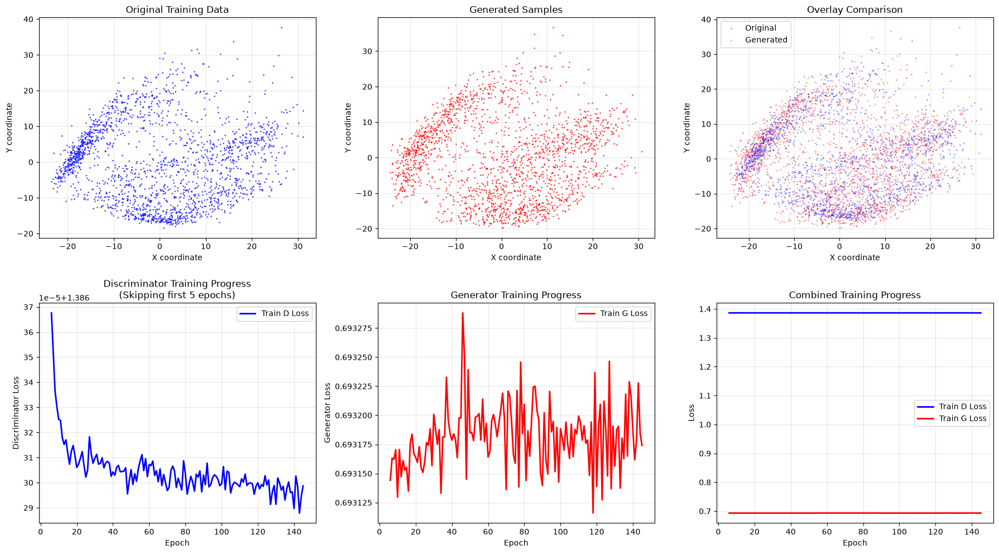

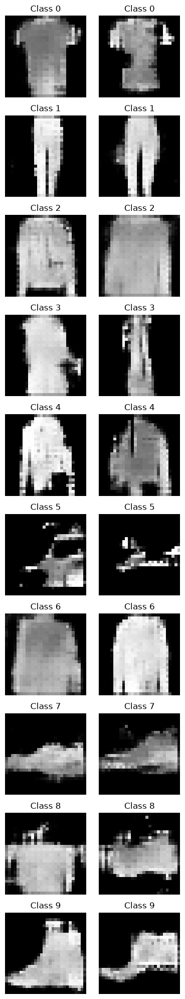

📈 Epoch 145 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6933

📊 Epoch 146/200
----------------------------------------
Epoch: 146 [0/60000 (0%)]	D_loss: 1.386247	G_loss: 0.693485
Epoch: 146 [6400/60000 (11%)]	D_loss: 1.386244	G_loss: 0.693255
Epoch: 146 [12800/60000 (21%)]	D_loss: 1.386285	G_loss: 0.693960
Epoch: 146 [19200/60000 (32%)]	D_loss: 1.386256	G_loss: 0.693464
Epoch: 146 [25600/60000 (43%)]	D_loss: 1.386276	G_loss: 0.693070
Epoch: 146 [32000/60000 (53%)]	D_loss: 1.386366	G_loss: 0.693303
Epoch: 146 [38400/60000 (64%)]	D_loss: 1.386281	G_loss: 0.692559
Epoch: 146 [44800/60000 (75%)]	D_loss: 1.386148	G_loss: 0.692720
Epoch: 146 [51200/60000 (85%)]	D_loss: 1.386370	G_loss: 0.693259
Epoch: 146 [57600/60000 (96%)]	D_loss: 1.386311	G_loss: 0.692829
====> Epoch: 146 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 146 Val D_loss: 1.3863, Val G_loss: 0.6932
📈 Epoch 146 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

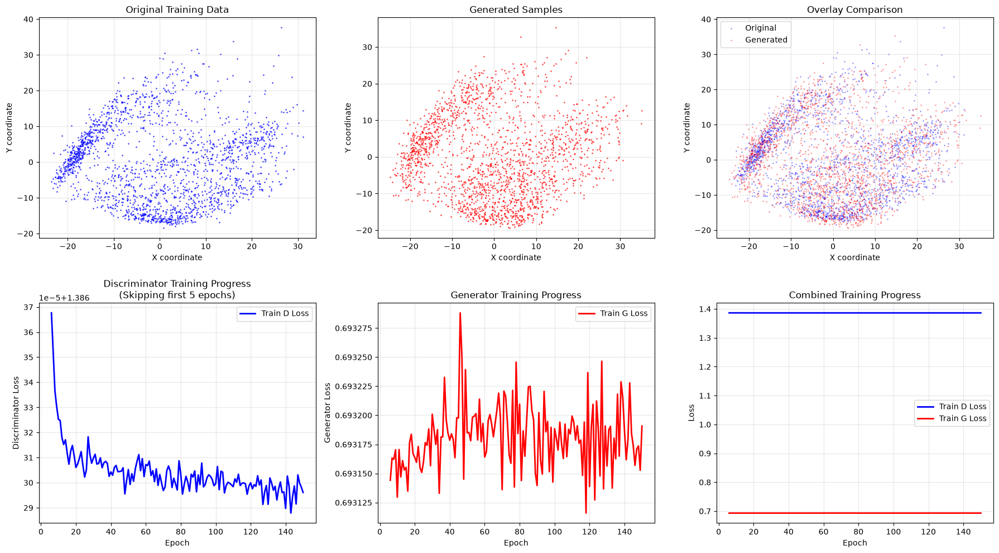

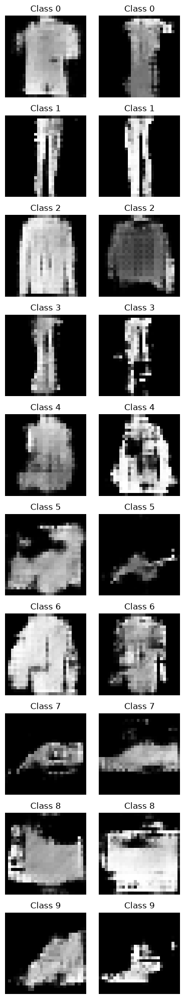

📈 Epoch 150 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6930

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	D_loss: 1.386353	G_loss: 0.692533
Epoch: 151 [6400/60000 (11%)]	D_loss: 1.386346	G_loss: 0.692216
Epoch: 151 [12800/60000 (21%)]	D_loss: 1.386320	G_loss: 0.692974
Epoch: 151 [19200/60000 (32%)]	D_loss: 1.386342	G_loss: 0.693099
Epoch: 151 [25600/60000 (43%)]	D_loss: 1.386273	G_loss: 0.693244
Epoch: 151 [32000/60000 (53%)]	D_loss: 1.386355	G_loss: 0.693880
Epoch: 151 [38400/60000 (64%)]	D_loss: 1.386479	G_loss: 0.693010
Epoch: 151 [44800/60000 (75%)]	D_loss: 1.386357	G_loss: 0.692839
Epoch: 151 [51200/60000 (85%)]	D_loss: 1.386223	G_loss: 0.693628
Epoch: 151 [57600/60000 (96%)]	D_loss: 1.386458	G_loss: 0.693129
====> Epoch: 151 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 151 Val D_loss: 1.3862, Val G_loss: 0.6937
📈 Epoch 151 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

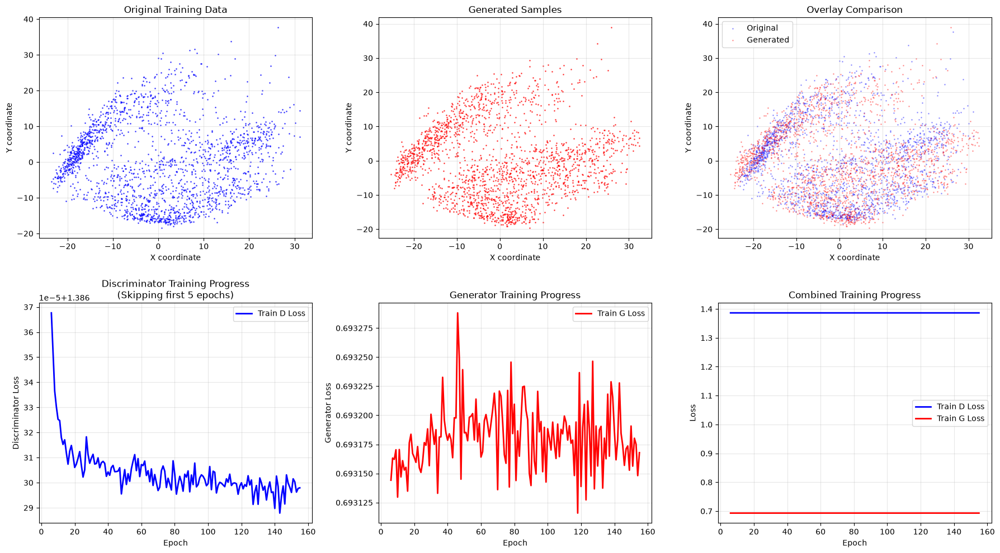

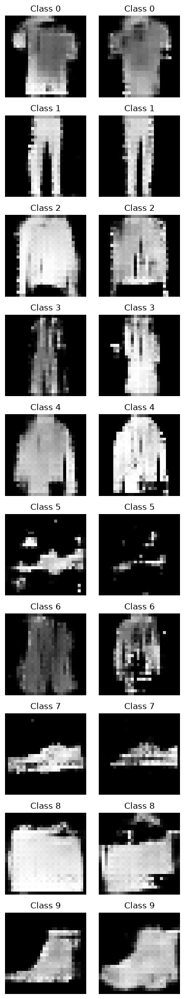

📈 Epoch 155 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932, Val G Loss: 0.6929

📊 Epoch 156/200
----------------------------------------
Epoch: 156 [0/60000 (0%)]	D_loss: 1.386243	G_loss: 0.693585
Epoch: 156 [6400/60000 (11%)]	D_loss: 1.386307	G_loss: 0.693158
Epoch: 156 [12800/60000 (21%)]	D_loss: 1.386427	G_loss: 0.692994
Epoch: 156 [19200/60000 (32%)]	D_loss: 1.386319	G_loss: 0.692517
Epoch: 156 [25600/60000 (43%)]	D_loss: 1.386261	G_loss: 0.693213
Epoch: 156 [32000/60000 (53%)]	D_loss: 1.386320	G_loss: 0.693215
Epoch: 156 [38400/60000 (64%)]	D_loss: 1.386313	G_loss: 0.693140
Epoch: 156 [44800/60000 (75%)]	D_loss: 1.386267	G_loss: 0.692994
Epoch: 156 [51200/60000 (85%)]	D_loss: 1.386291	G_loss: 0.693124
Epoch: 156 [57600/60000 (96%)]	D_loss: 1.386278	G_loss: 0.693291
====> Epoch: 156 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 156 Val D_loss: 1.3862, Val G_loss: 0.6934
📈 Epoch 156 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

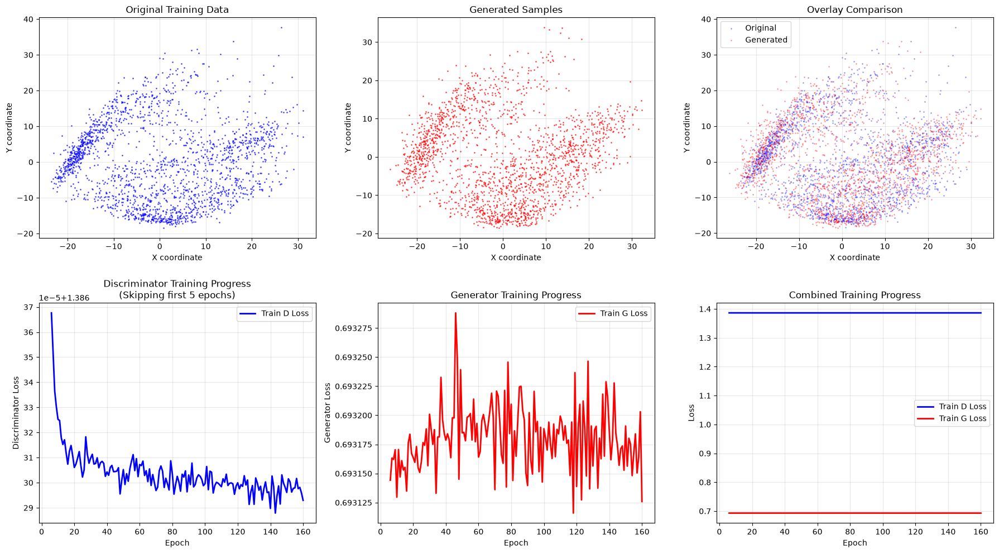

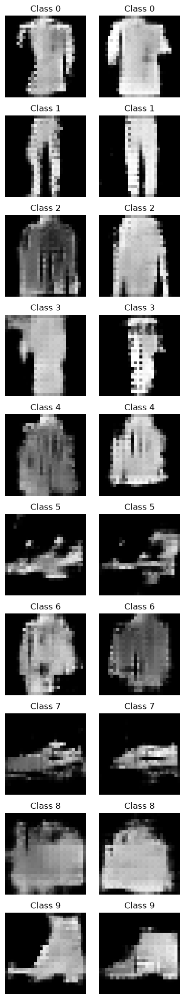

📈 Epoch 160 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6934

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	D_loss: 1.386250	G_loss: 0.692964
Epoch: 161 [6400/60000 (11%)]	D_loss: 1.386358	G_loss: 0.692808
Epoch: 161 [12800/60000 (21%)]	D_loss: 1.386291	G_loss: 0.693016
Epoch: 161 [19200/60000 (32%)]	D_loss: 1.386299	G_loss: 0.693584
Epoch: 161 [25600/60000 (43%)]	D_loss: 1.386237	G_loss: 0.693748
Epoch: 161 [32000/60000 (53%)]	D_loss: 1.386292	G_loss: 0.693090
Epoch: 161 [38400/60000 (64%)]	D_loss: 1.386315	G_loss: 0.693857
Epoch: 161 [44800/60000 (75%)]	D_loss: 1.386308	G_loss: 0.692532
Epoch: 161 [51200/60000 (85%)]	D_loss: 1.386430	G_loss: 0.693106
Epoch: 161 [57600/60000 (96%)]	D_loss: 1.386558	G_loss: 0.693600
====> Epoch: 161 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 161 Val D_loss: 1.3862, Val G_loss: 0.6931
📈 Epoch 161 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

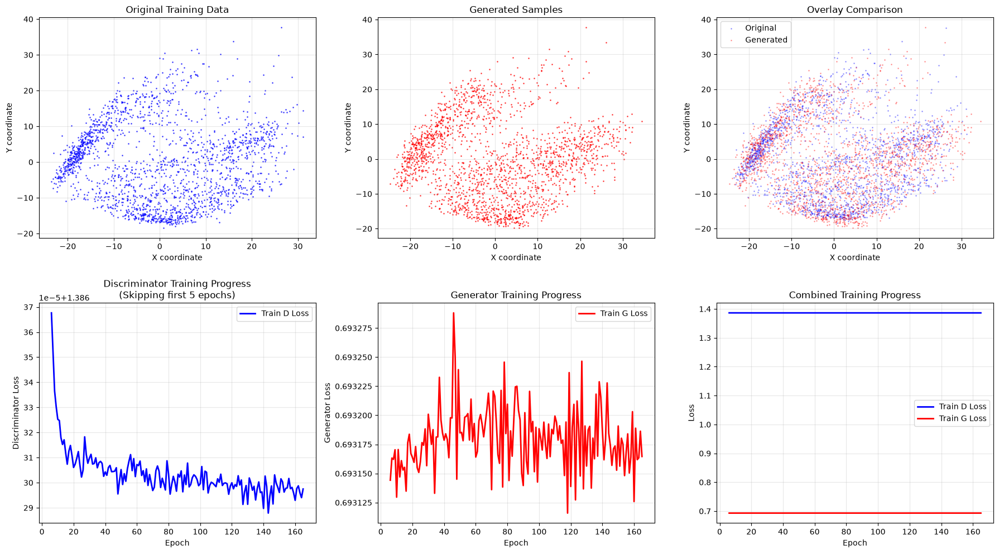

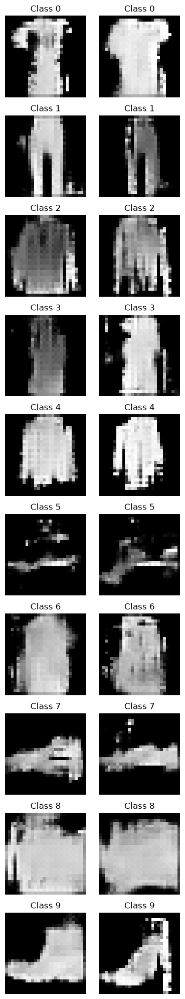

📈 Epoch 165 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6922

📊 Epoch 166/200
----------------------------------------
Epoch: 166 [0/60000 (0%)]	D_loss: 1.386274	G_loss: 0.692760
Epoch: 166 [6400/60000 (11%)]	D_loss: 1.386278	G_loss: 0.693153
Epoch: 166 [12800/60000 (21%)]	D_loss: 1.386279	G_loss: 0.693421
Epoch: 166 [19200/60000 (32%)]	D_loss: 1.386277	G_loss: 0.692426
Epoch: 166 [25600/60000 (43%)]	D_loss: 1.386262	G_loss: 0.693189
Epoch: 166 [32000/60000 (53%)]	D_loss: 1.386293	G_loss: 0.694510
Epoch: 166 [38400/60000 (64%)]	D_loss: 1.386275	G_loss: 0.693014
Epoch: 166 [44800/60000 (75%)]	D_loss: 1.386227	G_loss: 0.693210
Epoch: 166 [51200/60000 (85%)]	D_loss: 1.386291	G_loss: 0.693430
Epoch: 166 [57600/60000 (96%)]	D_loss: 1.386332	G_loss: 0.692844
====> Epoch: 166 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 166 Val D_loss: 1.3864, Val G_loss: 0.6931
📈 Epoch 166 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

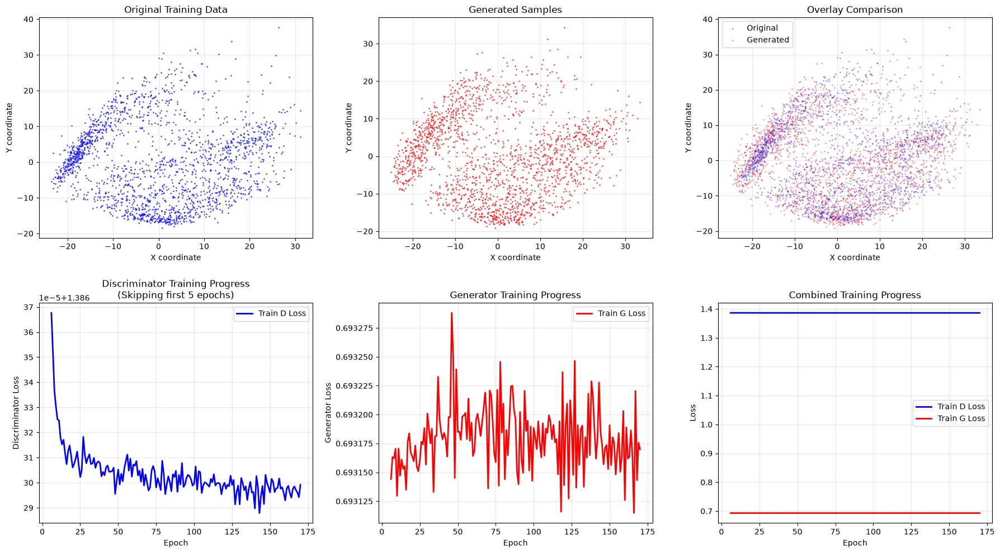

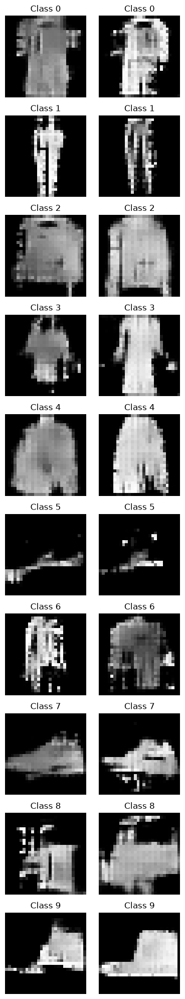

📈 Epoch 170 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6934

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	D_loss: 1.386293	G_loss: 0.693031
Epoch: 171 [6400/60000 (11%)]	D_loss: 1.386235	G_loss: 0.693142
Epoch: 171 [12800/60000 (21%)]	D_loss: 1.386229	G_loss: 0.693648
Epoch: 171 [19200/60000 (32%)]	D_loss: 1.386217	G_loss: 0.693222
Epoch: 171 [25600/60000 (43%)]	D_loss: 1.386340	G_loss: 0.693070
Epoch: 171 [32000/60000 (53%)]	D_loss: 1.386379	G_loss: 0.692986
Epoch: 171 [38400/60000 (64%)]	D_loss: 1.386303	G_loss: 0.693180
Epoch: 171 [44800/60000 (75%)]	D_loss: 1.386311	G_loss: 0.692706
Epoch: 171 [51200/60000 (85%)]	D_loss: 1.386361	G_loss: 0.693222
Epoch: 171 [57600/60000 (96%)]	D_loss: 1.386353	G_loss: 0.692608
====> Epoch: 171 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 171 Val D_loss: 1.3864, Val G_loss: 0.6930
📈 Epoch 171 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

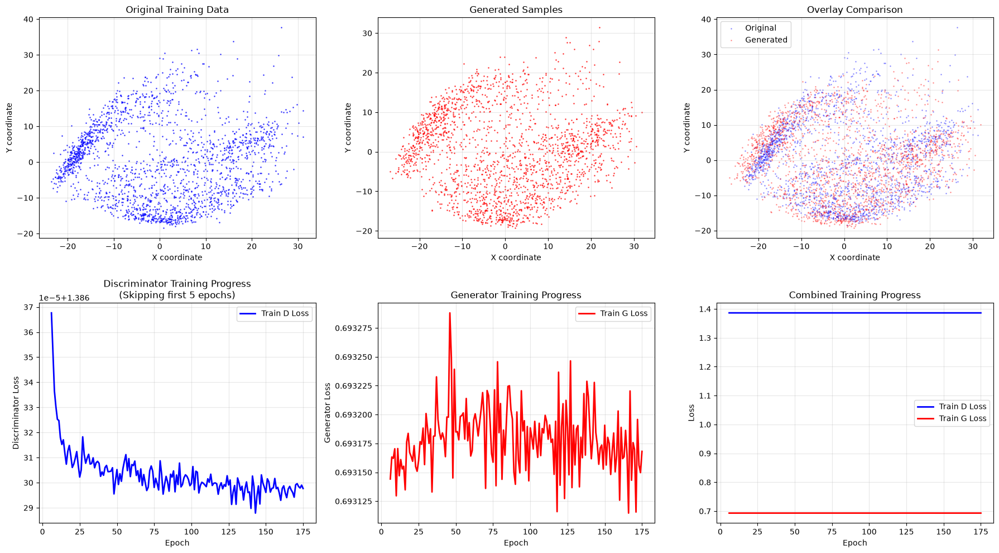

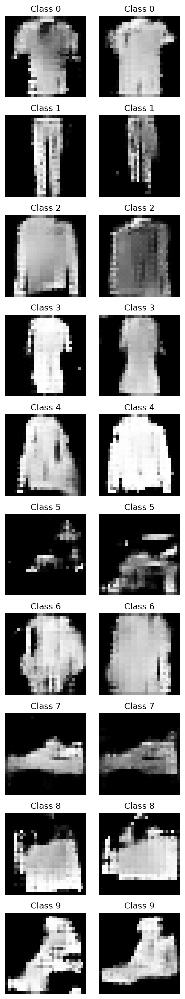

📈 Epoch 175 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6931

📊 Epoch 176/200
----------------------------------------
Epoch: 176 [0/60000 (0%)]	D_loss: 1.386393	G_loss: 0.693529
Epoch: 176 [6400/60000 (11%)]	D_loss: 1.386286	G_loss: 0.692639
Epoch: 176 [12800/60000 (21%)]	D_loss: 1.386368	G_loss: 0.693462
Epoch: 176 [19200/60000 (32%)]	D_loss: 1.386261	G_loss: 0.693167
Epoch: 176 [25600/60000 (43%)]	D_loss: 1.386295	G_loss: 0.692933
Epoch: 176 [32000/60000 (53%)]	D_loss: 1.386277	G_loss: 0.693552
Epoch: 176 [38400/60000 (64%)]	D_loss: 1.386297	G_loss: 0.692805
Epoch: 176 [44800/60000 (75%)]	D_loss: 1.386300	G_loss: 0.693471
Epoch: 176 [51200/60000 (85%)]	D_loss: 1.386222	G_loss: 0.692879
Epoch: 176 [57600/60000 (96%)]	D_loss: 1.386318	G_loss: 0.693106
====> Epoch: 176 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 176 Val D_loss: 1.3862, Val G_loss: 0.6927
📈 Epoch 176 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

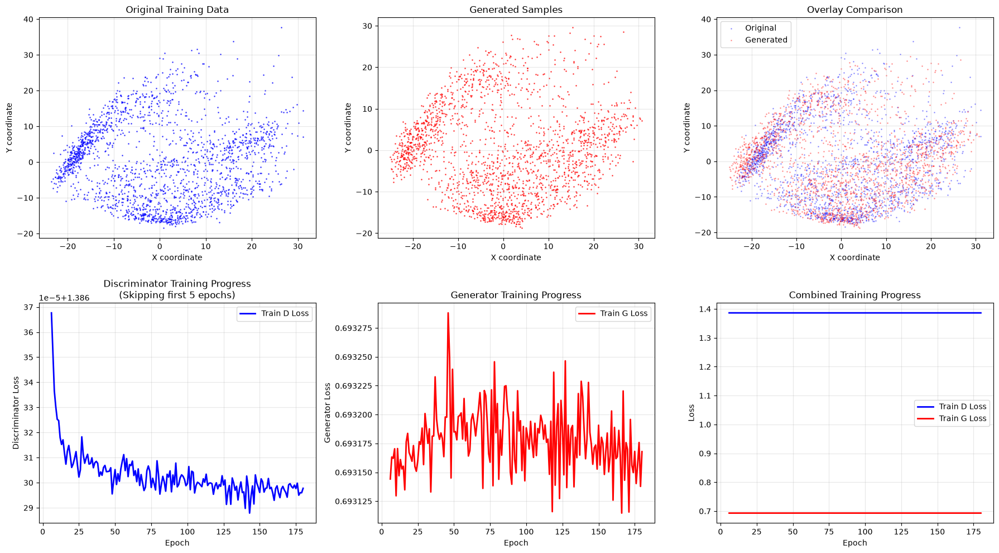

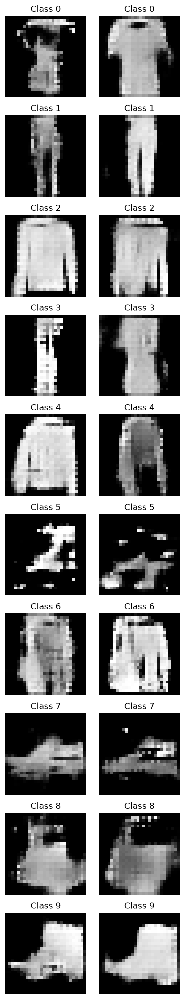

📈 Epoch 180 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6925

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	D_loss: 1.386366	G_loss: 0.693296
Epoch: 181 [6400/60000 (11%)]	D_loss: 1.386365	G_loss: 0.693088
Epoch: 181 [12800/60000 (21%)]	D_loss: 1.386282	G_loss: 0.693231
Epoch: 181 [19200/60000 (32%)]	D_loss: 1.386302	G_loss: 0.692954
Epoch: 181 [25600/60000 (43%)]	D_loss: 1.386378	G_loss: 0.693489
Epoch: 181 [32000/60000 (53%)]	D_loss: 1.386308	G_loss: 0.694048
Epoch: 181 [38400/60000 (64%)]	D_loss: 1.386345	G_loss: 0.691414
Epoch: 181 [44800/60000 (75%)]	D_loss: 1.386396	G_loss: 0.692766
Epoch: 181 [51200/60000 (85%)]	D_loss: 1.386186	G_loss: 0.694019
Epoch: 181 [57600/60000 (96%)]	D_loss: 1.386323	G_loss: 0.692309
====> Epoch: 181 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 181 Val D_loss: 1.3864, Val G_loss: 0.6938
📈 Epoch 181 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

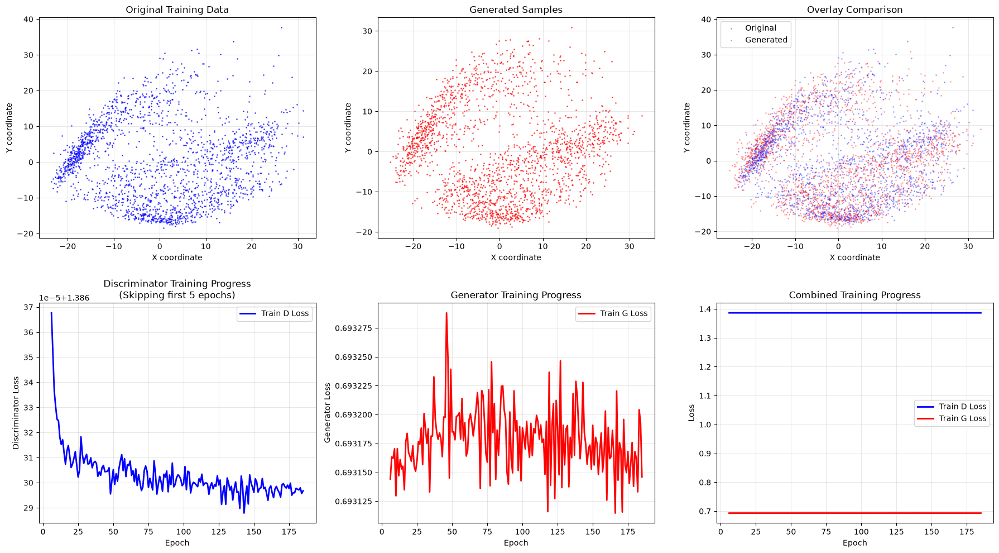

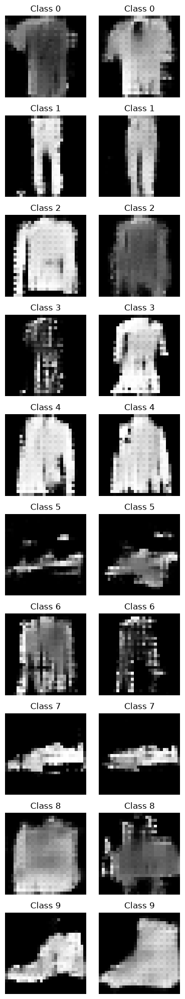

📈 Epoch 185 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6944

📊 Epoch 186/200
----------------------------------------
Epoch: 186 [0/60000 (0%)]	D_loss: 1.386278	G_loss: 0.693775
Epoch: 186 [6400/60000 (11%)]	D_loss: 1.386274	G_loss: 0.692619
Epoch: 186 [12800/60000 (21%)]	D_loss: 1.386313	G_loss: 0.692731
Epoch: 186 [19200/60000 (32%)]	D_loss: 1.386285	G_loss: 0.693474
Epoch: 186 [25600/60000 (43%)]	D_loss: 1.386301	G_loss: 0.692722
Epoch: 186 [32000/60000 (53%)]	D_loss: 1.386284	G_loss: 0.693192
Epoch: 186 [38400/60000 (64%)]	D_loss: 1.386298	G_loss: 0.692704
Epoch: 186 [44800/60000 (75%)]	D_loss: 1.386285	G_loss: 0.692911
Epoch: 186 [51200/60000 (85%)]	D_loss: 1.386279	G_loss: 0.692886
Epoch: 186 [57600/60000 (96%)]	D_loss: 1.386296	G_loss: 0.693323
====> Epoch: 186 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 186 Val D_loss: 1.3863, Val G_loss: 0.6933
📈 Epoch 186 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

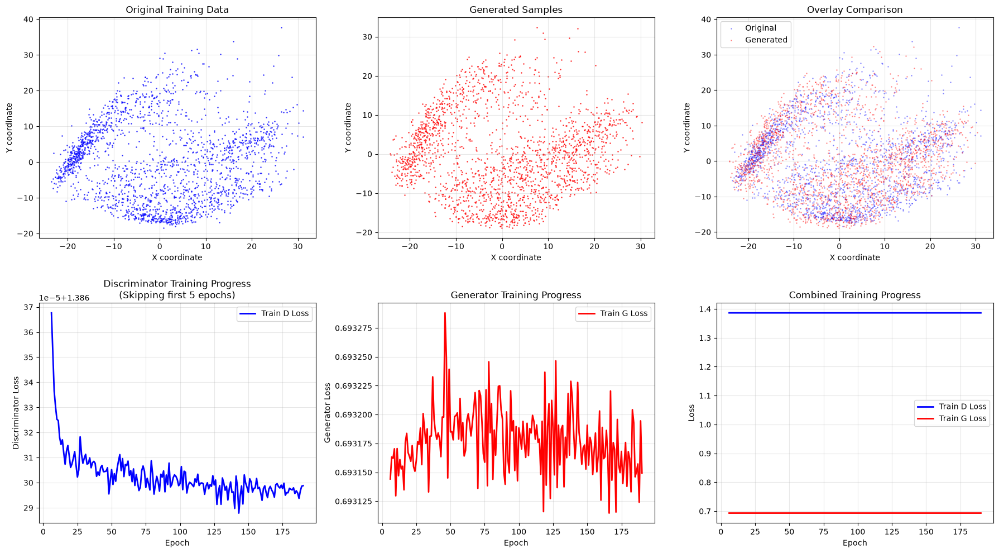

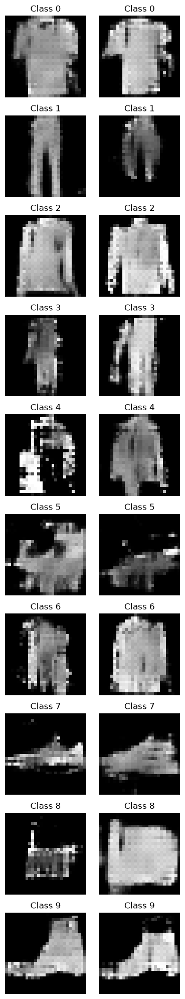

📈 Epoch 190 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6931, Val G Loss: 0.6929

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	D_loss: 1.386304	G_loss: 0.693294
Epoch: 191 [6400/60000 (11%)]	D_loss: 1.386297	G_loss: 0.694019
Epoch: 191 [12800/60000 (21%)]	D_loss: 1.386314	G_loss: 0.693400
Epoch: 191 [19200/60000 (32%)]	D_loss: 1.386267	G_loss: 0.693935
Epoch: 191 [25600/60000 (43%)]	D_loss: 1.386317	G_loss: 0.692867
Epoch: 191 [32000/60000 (53%)]	D_loss: 1.386346	G_loss: 0.693152
Epoch: 191 [38400/60000 (64%)]	D_loss: 1.386386	G_loss: 0.694022
Epoch: 191 [44800/60000 (75%)]	D_loss: 1.386289	G_loss: 0.693497
Epoch: 191 [51200/60000 (85%)]	D_loss: 1.386270	G_loss: 0.692131
Epoch: 191 [57600/60000 (96%)]	D_loss: 1.386276	G_loss: 0.694130
====> Epoch: 191 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 191 Val D_loss: 1.3863, Val G_loss: 0.6936
📈 Epoch 191 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

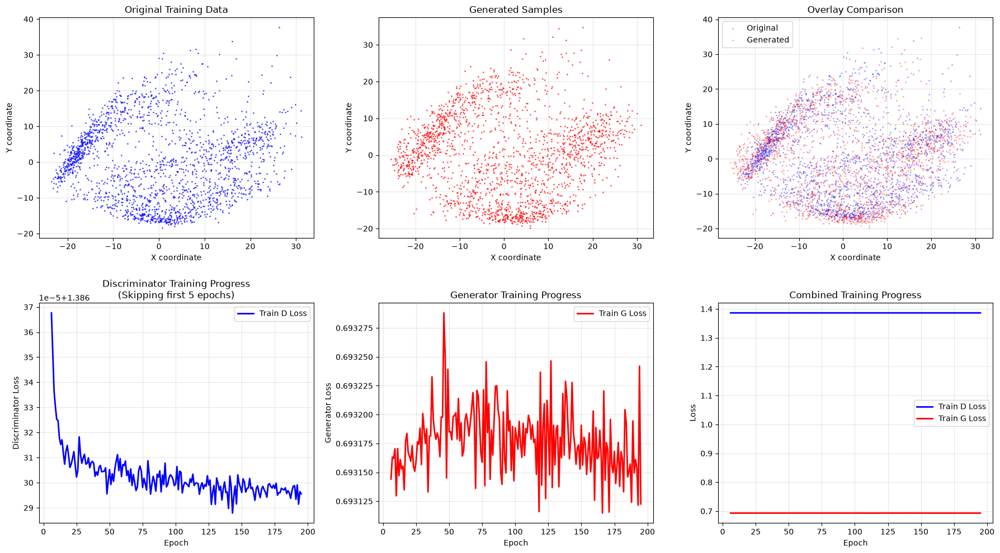

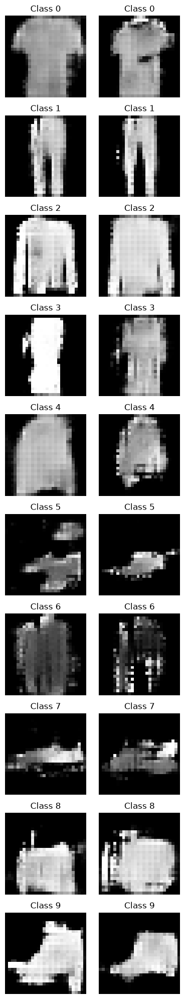

📈 Epoch 195 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6931, Val G Loss: 0.6937

📊 Epoch 196/200
----------------------------------------
Epoch: 196 [0/60000 (0%)]	D_loss: 1.386414	G_loss: 0.693503
Epoch: 196 [6400/60000 (11%)]	D_loss: 1.386280	G_loss: 0.692845
Epoch: 196 [12800/60000 (21%)]	D_loss: 1.386424	G_loss: 0.692629
Epoch: 196 [19200/60000 (32%)]	D_loss: 1.386239	G_loss: 0.693533
Epoch: 196 [25600/60000 (43%)]	D_loss: 1.386301	G_loss: 0.693242
Epoch: 196 [32000/60000 (53%)]	D_loss: 1.386306	G_loss: 0.692860
Epoch: 196 [38400/60000 (64%)]	D_loss: 1.386323	G_loss: 0.693409
Epoch: 196 [44800/60000 (75%)]	D_loss: 1.386301	G_loss: 0.693471
Epoch: 196 [51200/60000 (85%)]	D_loss: 1.386330	G_loss: 0.692610
Epoch: 196 [57600/60000 (96%)]	D_loss: 1.386295	G_loss: 0.693041
====> Epoch: 196 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 196 Val D_loss: 1.3863, Val G_loss: 0.6934
📈 Epoch 196 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

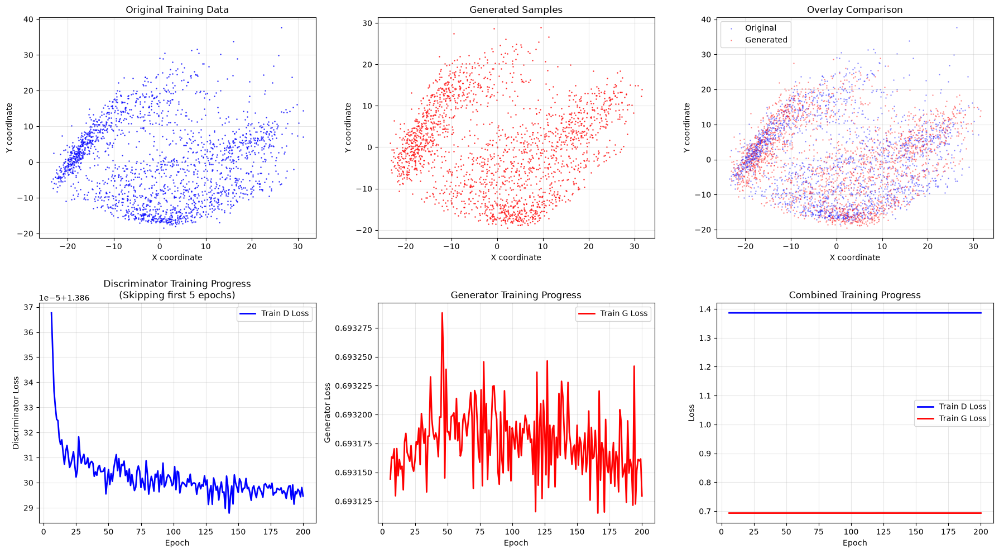

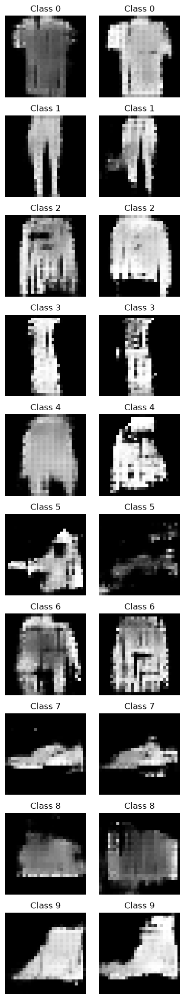

📈 Epoch 200 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6931, Val G Loss: 0.6922

🎉 Training completed!

🎨 Final comprehensive visualization:


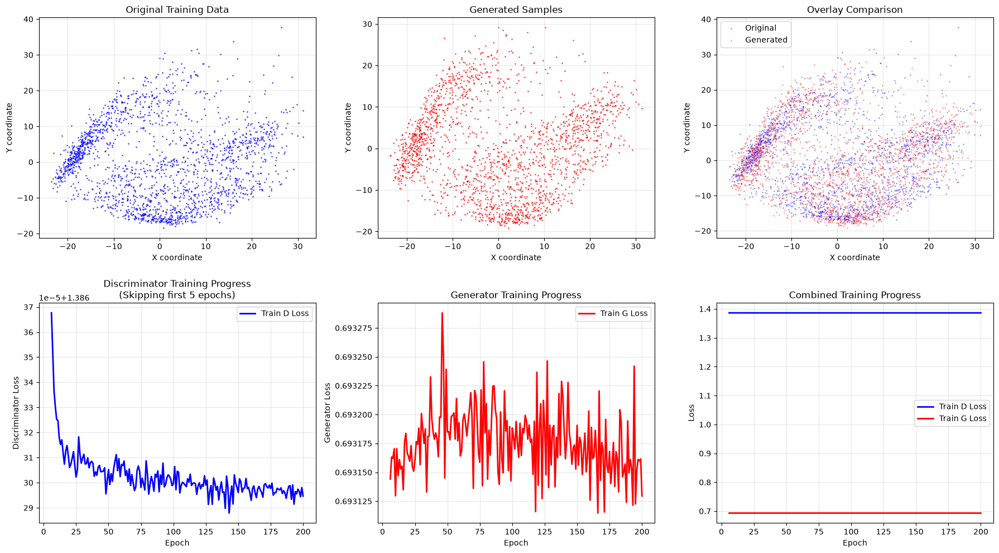

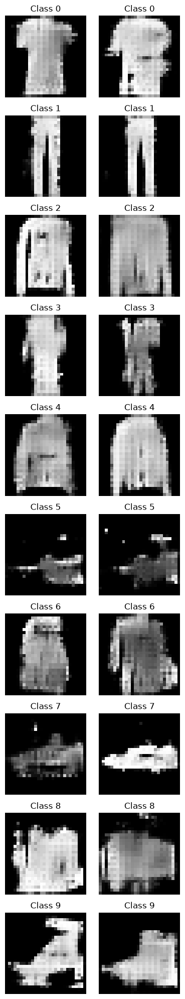

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


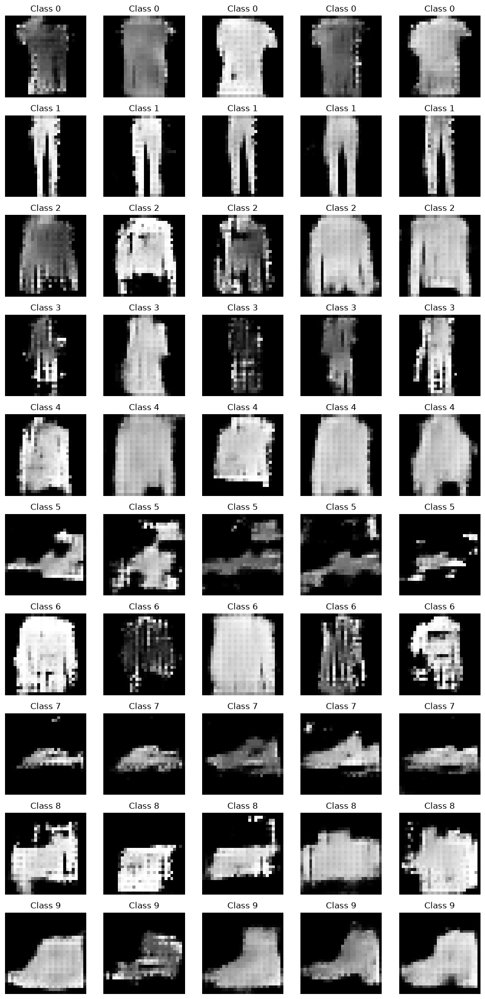

Real data confidence with matching classes: 0.501
Fake data confidence with requested classes: 0.500


In [15]:
TARGET_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SAMPLES_PER_CLASS = 5

visualize_class_samples(TARGET_CLASSES, samples_per_class=SAMPLES_PER_CLASS)

generated_sevens = generate_samples(20, classes=7)
generated_digits = generate_samples(len(TARGET_CLASSES), classes=TARGET_CLASSES)

generator.eval()
discriminator.eval()
with torch.no_grad():
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_classes = train_data.targets[:100].to(device)
    real_pred = discriminator(real_batch, real_classes).mean().item()

    fake_classes = torch.tensor(TARGET_CLASSES, device=device).repeat(100)[:100]
    noise = torch.randn(100, NOISE_DIM, device=device)
    fake_batch = generator(noise, fake_classes)
    fake_pred = discriminator(fake_batch, fake_classes).mean().item()

print(f'Real data confidence with matching classes: {real_pred:.3f}')
print(f'Fake data confidence with requested classes: {fake_pred:.3f}')
